# Notebook 3: Robuste Verteilungsdiagnostik

**Statistik für Data Science** · Kurs 3,906 · Bachelor Computer Science · HS2026
Universität St. Gallen

---
### Projektteam:
- Andrin Greitmann
- Noah Appenzeller
- Manuel Schmid

---

Dieses Notebook führt die Inhalte von **VL03 (Verteilungen visualisieren und diagnostizieren)** in Python aus, zusammen mit den Ausreisserregeln aus dem Begleitnotebook zu VL03.

## 0. Setup
Importiert `pandas`, `numpy`, `seaborn` und `matplotlib` und setzt den Seed.

In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Seed: Startwert für den Zufallsgenerator. Gleicher Seed bei jedem Durchlauf damit Resultate deterministisch & reproduzierbar sind. 
# Den Wert selbst haben wir beliebig gewählt, wir haben ihn als erstes vor der Analyse gewählt und danach nicht mehr geändert.
# Der Seed wird für alles Zufällige in allen Notebooks verwendet.
SEED = 2001
RNG = np.random.default_rng(SEED)

# Plot-Defauls
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (7.5, 4.2)
plt.rcParams["figure.dpi"] = 110
plt.rcParams["axes.titlesize"] = 13
plt.rcParams["axes.labelsize"] = 11

In [2]:
import sys

print("Python  ", sys.version.split()[0])
for modul in (np, pd, sns):
    print(f"{modul.__name__:8s}", modul.__version__)
print("Seed    ", SEED)

Python   3.14.4
numpy    2.5.3
pandas   3.0.6
seaborn  0.13.2
Seed     2001


### Unseren Datensatz laden

In [3]:
from ucimlrepo import fetch_ucirepo

# Datensatz direkt aus dem UCI Repository laden (ID 117 = Census-Income KDD)
census_income_kdd = fetch_ucirepo(id=117)

# Etwas spezielles an unserem Datenset: ucimlrepo liefert die Daten aufgeteilt in Features und Target. 
# (Wahrscheinlich für Machine Learning Projekte/Algorithmen)
# Target ist das Einkommen (über/unter 50K), Features sind alle anderen Merkmale.
X = census_income_kdd.data.features
y = census_income_kdd.data.targets

# Für die EDA wollten wir alle Spalten in einem DataFrame damit das Einkommen mit den anderen Merkmalen verglichen werden kann.
# join() funktioniert hier zum Glück recht einfach, weil X und y dieselben Zeilen in derselben Reihenfolge haben.
census = X.join(y)
 
# Leerzeichen bei den Textspalten entfernen
text_spalten = census.select_dtypes(exclude="number").columns
census[text_spalten] = census[text_spalten].apply(lambda s: s.str.strip())

# Wir wollen die Spalten umbenennen, sodass es ersichtlicher ist, mit was wir arbeiten
# Dies ist jedoch in den Metadaten der folgenden Ausgabe noch nicht ersichtlich, erst bei allen späteren Ausgaben.

spalten_umbenennung = {
    "AAGE": "AGE", "ACLSWKR": "CLASS_OF_WORKER", "ADTINK": "INDUSTRY_CODE",      
    "ADTOCC": "OCCUPATION_CODE", "AHGA": "EDUCATION", "AHSCOL": "ENROLLED_IN_EDU",
    "AMARITL": "MARITAL_STATUS", "AMJIND": "MAJOR_INDUSTRY", "AMJOCC": "MAJOR_OCCUPATION",
    "ARACE": "RACE", "AREORGN": "HISPANIC_ORIGIN", "ASEX": "SEX",
    "AUNMEM": "LABOR_UNION_MEMBER", "AUNTYPE": "UNEMPLOYMENT_REASON", "AWKSTAT": "EMPLOYMENT_STATUS",
    "CAPGAIN": "CAPITAL_GAINS", "GAPLOSS": "CAPITAL_LOSSES", "DIVVAL": "DIVIDENDS",
    "FILESTAT": "TAX_FILER_STATUS", "GRINREG": "PREV_REGION", "GRINST": "PREV_STATE",
    "HHDFMX": "HOUSEHOLD_STAT_DETAILED", "HHDREL": "HOUSEHOLD_SUMMARY", "MARSUPWRT": "WEIGHT",
    "MIGMTR1": "MIGRATION_MSA", "MIGMTR3": "MIGRATION_REG", "MIGMTR4": "MIGRATION_WITHIN_REG",
    "MIGSAME": "SAME_HOUSE_1YR", "MIGSUN": "MIGRATION_SUNBELT", "NOEMP": "NUM_EMPLOYEES",
    "PARENT": "PARENTS_PRESENT", "PEFNTVTY": "BIRTH_COUNTRY_FATHER", "PEMNTVTY": "BIRTH_COUNTRY_MOTHER",
    "PENATVTY": "BIRTH_COUNTRY_SELF", "PRCITSHP": "CITIZENSHIP", "SEOTR": "SELF_EMPLOYED",
    "VETQVA": "VET_QUESTIONNAIRE", "VETYN": "VETERANS_BENEFITS", "WKSWORK": "WEEKS_WORKED",
    "AHRSPAY": "WAGE_PER_HOUR", "year": "YEAR", "income": "INCOME"
}
census = census.rename(columns=spalten_umbenennung)

# Metadaten: Herkunft, Beschreibung und Erhebung des Datensatzes (Damit wir auf Bias analysieren können)
print("Metadata: " + str(census_income_kdd.metadata))

print(f"Rows: {census.shape[0]}, Columns: {census.shape[1]}")

# Variablenbeschreibung: Name, Typ und Bedeutung jeder Spalte (Grundlage um später Messniveau zu bestimmen)
print("Variable descriptions:")

# display(census_income_kdd.variables)

Metadata: {'uci_id': 117, 'name': 'Census-Income (KDD)', 'repository_url': 'https://archive.ics.uci.edu/dataset/117/census+income+kdd', 'data_url': 'https://archive.ics.uci.edu/static/public/117/data.csv', 'abstract': 'This data set contains weighted census data extracted from the 1994 and 1995 current population surveys conducted by the U.S. Census Bureau.', 'area': 'Social Science', 'tasks': ['Classification'], 'characteristics': ['Multivariate'], 'num_instances': 299285, 'num_features': 41, 'feature_types': ['Categorical', 'Integer'], 'demographics': ['Age', 'Occupation', 'Education Level', 'Marital Status', 'Race', 'Sex', 'Other', 'Nationality', 'Income'], 'target_col': ['income'], 'index_col': None, 'has_missing_values': 'yes', 'missing_values_symbol': 'NaN', 'year_of_dataset_creation': 2000, 'last_updated': 'Fri Mar 08 2024', 'dataset_doi': '10.24432/C5N30T', 'creators': [], 'intro_paper': None, 'additional_info': {'summary': "This data set contains weighted census data extracted

### Datensatz bereinigen
Hier wenden wir die Bereinigung aus NB01 (Abschnitt 5) an, inklusive der neuen Spalten aus den originalen CPS-Daten (NB01, 5.1). Danach ist `census` der bereinigte Datensatz, die Rohdaten bleiben als `census_raw` verfügbar.

In [4]:
# Die Abfrage sorgt dafür, dass ein zweites Ausführen dieser Zelle wieder
# bei den Rohdaten startet (sonst würde z.B. der Stundenlohn ein zweites Mal durch 100 geteilt).
if "census_raw" not in globals():
    census_raw = census
census = census_raw.copy()

# 1) Migrationsblock 1995 wurde nicht erhoben, auch wo "Not in universe" steht (3.2)
jahr_95 = census["YEAR"] == 95
census.loc[jahr_95, ["SAME_HOUSE_1YR", "PREV_REGION"]] = np.nan

# 2) Die Bundesstaaten passen nicht zur Region, die Spalte verwenden wir nicht (3.3)
census = census.drop(columns="PREV_STATE")

# 3) Stundenlohn: 0 bei Erwerbstätigen heisst "nicht erfasst" (3.2), die Einheit ist Cents (4.2)
nicht_erfasst = (census["WEEKS_WORKED"] > 0) & (census["WAGE_PER_HOUR"] == 0)
census["WAGE_PER_HOUR"] = census["WAGE_PER_HOUR"].astype(float).where(~nicht_erfasst) / 100

# 4) Antwortausfall bei der hispanischen Herkunft (3.2)
census["HISPANIC_ORIGIN"] = census["HISPANIC_ORIGIN"].replace({"Do not know": np.nan, "NA": np.nan})

# 5) Geburtsländer nicht imputieren, sondern als eigene Kategorie führen (3.4 und 3.7)
census["BIRTH_COUNTRY_SELF"] = census["BIRTH_COUNTRY_SELF"].fillna("Foreign, Unknown")
eltern = ["BIRTH_COUNTRY_FATHER", "BIRTH_COUNTRY_MOTHER"]
census[eltern] = census[eltern].fillna("Unknown")

# 6) Messniveau im Datentyp festhalten, damit pandas keine unzulässigen Mittelwerte rechnet (1 und 4)
BILDUNG = [
    "Children",
    "Less than 1st grade",
    "1st 2nd 3rd or 4th grade",
    "5th or 6th grade",
    "7th and 8th grade",
    "9th grade",
    "10th grade",
    "11th grade",
    "12th grade no diploma",
    "High school graduate",
    "Some college but no degree",
    "Associates degree-occup /vocational",
    "Associates degree-academic program",
    "Bachelors degree(BA AB BS)",
    "Masters degree(MA MS MEng MEd MSW MBA)",
    "Prof school degree (MD DDS DVM LLB JD)",
    "Doctorate degree(PhD EdD)",
]
census["EDUCATION"] = census["EDUCATION"].astype(pd.CategoricalDtype(BILDUNG, ordered=True))
# NUM_EMPLOYEES sind Grössenklassen 0 bis 6, also ordinal und keine Anzahl (4.1)
census["NUM_EMPLOYEES"] = census["NUM_EMPLOYEES"].astype(pd.CategoricalDtype(list(range(7)), ordered=True))
# Nominale Codes, die als Zahl gespeichert sind (1 und 4.1)
nominale_codes = ["INDUSTRY_CODE", "OCCUPATION_CODE", "SELF_EMPLOYED", "VETERANS_BENEFITS"]
census[nominale_codes] = census[nominale_codes].astype("category")

# 7) Neue Spalten aus den originalen CPS-Dateien: exaktes Einkommen, Arbeitsstunden, Wohnort usw. (NB01, 5.1)
zusatz = pd.read_csv("../zusatzdaten/census_zusatz.csv.gz", index_col="ROW")
# Kontrolle: Die Zusatzdaten müssen Zeile für Zeile zu census passen
assert (zusatz["CHECK_AGE"].to_numpy() == census["AGE"].to_numpy()).all(), "Zusatzdaten passen nicht zu census"
assert np.allclose(zusatz["CHECK_WEIGHT"].to_numpy(), census["WEIGHT"].to_numpy()), "Zusatzdaten passen nicht zu census"
census = census.join(zusatz.drop(columns=["CHECK_AGE", "CHECK_WEIGHT"]))
ARMUT = ["Below poverty line", "100-124% of poverty line", "125-149% of poverty line", "150%+ of poverty line"]
census["POVERTY_LEVEL"] = census["POVERTY_LEVEL"].astype(pd.CategoricalDtype(ARMUT, ordered=True))

# Kontrolle: Eine Bildungskategorie, die nicht in BILDUNG steht, würde still zu NaN werden
assert census["EDUCATION"].notna().all(), "Unbekannte Kategorie in EDUCATION"

print(f"census (bereinigt): {census.shape[0]} Zeilen, {census.shape[1]} Spalten")
print(f"census_raw:         {census_raw.shape[0]} Zeilen, {census_raw.shape[1]} Spalten\n")
fehlend = census.isna().sum()
print("Fehlende Werte nach der Bereinigung:")
print(fehlend[fehlend > 0].sort_values(ascending=False))

census (bereinigt): 199523 Zeilen, 49 Spalten
census_raw:         199523 Zeilen, 42 Spalten

Fehlende Werte nach der Bereinigung:
PREV_REGION             99696
MIGRATION_MSA           99696
MIGRATION_REG           99696
MIGRATION_WITHIN_REG    99696
MIGRATION_SUNBELT       99696
SAME_HOUSE_1YR          99696
WAGE_PER_HOUR           92519
HOUSEHOLD_INCOME        10832
POVERTY_LEVEL            4189
HISPANIC_ORIGIN          1180
METRO                     481
TOTAL_INCOME              231
STATE                     209
REGION                    198
EARNINGS                   47
HOURS_PER_WEEK             41
dtype: int64


### Variablen und Konventionen in diesem Notebook

VL03 fragt, wie man die Form einer Verteilung zeigt, ohne sie zu erfinden, wie man Gruppen vergleicht und wie man eine Form gegen eine Referenz prüft. Wir arbeiten vor allem mit dem Arbeitseinkommen der Vollzeit-Erwerbstätigen.

| Name im Notebook | Spalte | Personen | Einheit |
|---|---|---|---|
| `lohn_vollzeit` | `EARNINGS` | Vollzeit-Ganzjahres-Erwerbstätige (mind. 50 Wochen und üblicherweise mind. 35 Stunden pro Woche gearbeitet), Arbeitseinkommen > 0 | USD pro Jahr |
| `einkommen` | `TOTAL_INCOME` | alle Personen ab 15 Jahren | USD pro Jahr |
| `stundenlohn` | `WAGE_PER_HOUR` | Personen, die im Stundenlohn bezahlt werden (Wert > 0) | USD pro Stunde |
| `bildungsgruppe` | aus `EDUCATION` | 6 Gruppen vom fehlenden Abschluss bis "Master und höher" | |
| | `AGE`, `WEEKS_WORKED`, `HOURS_PER_WEEK` | je nach Abschnitt | Jahre, Wochen, Stunden |

Alle Kennzahlen sind **ungewichtet** und beschreiben die Stichprobe. Die Einkommen beziehen sich auf das Jahr vor der Befragung.

In [5]:
# Farben für alle Plots in diesem Notebook
FARBE_VORHER = "#85837c"      # grau: Ausgangslage
FARBE_NACHHER = "#4a3aa7"     # violett: nach dem Schritt
FARBE_MITTELWERT = "#2a78d6"  # blau, durchgezogene Linie
FARBE_MEDIAN = "#eb6834"      # orange, gestrichelte Linie
FARBE_FRAUEN = "#eb6834"
FARBE_MAENNER = "#2a78d6"


def zahl(x, stellen=0):
    """Zahl mit Apostroph als Tausendertrennzeichen, z.B. 19'798."""
    return f"{x:,.{stellen}f}".replace(",", "'")


BILDUNGSGRUPPEN = {
    "High school graduate": "High School",
    "Some college but no degree": "College ohne Abschluss",
    "Associates degree-occup /vocational": "Associate",
    "Associates degree-academic program": "Associate",
    "Bachelors degree(BA AB BS)": "Bachelor",
    "Masters degree(MA MS MEng MEd MSW MBA)": "Master und höher",
    "Prof school degree (MD DDS DVM LLB JD)": "Master und höher",
    "Doctorate degree(PhD EdD)": "Master und höher",
}
REIHENFOLGE = ["ohne Abschluss", "High School", "College ohne Abschluss", "Associate", "Bachelor", "Master und höher"]
KURZ = ["ohne\nAbschluss", "High\nSchool", "College ohne\nAbschluss", "Associate", "Bachelor", "Master\nund höher"]

ab15 = census[census["AGE"] >= 15]
einkommen = ab15["TOTAL_INCOME"].dropna()
vollzeit = census[(census["WEEKS_WORKED"] >= 50) & (census["HOURS_PER_WEEK"] >= 35) & (census["EARNINGS"] > 0)]
lohn_vollzeit = vollzeit["EARNINGS"]
bildungsgruppe = vollzeit["EDUCATION"].astype(str).map(BILDUNGSGRUPPEN).fillna("ohne Abschluss")
stundenlohn = census.loc[census["WAGE_PER_HOUR"] > 0, "WAGE_PER_HOUR"]

print(f"lohn_vollzeit: n = {len(lohn_vollzeit)}")
print(f"einkommen:     n = {len(einkommen)}")
print(f"stundenlohn:   n = {len(stundenlohn)}")
print(bildungsgruppe.value_counts().reindex(REIHENFOLGE))

lohn_vollzeit: n = 63186
einkommen:     n = 151876
stundenlohn:   n = 11304
EDUCATION
ohne Abschluss             6254
High School               21148
College ohne Abschluss    12392
Associate                  5540
Bachelor                  11797
Master und höher           6055
Name: count, dtype: int64


---

## 1. Histogramm und KDE

Wie macht man die Form einer Verteilung sichtbar, ohne sie zu erfinden? Klassen und Bandbreite sind keine Nebensache, sie bestimmen, welche Form man überhaupt sieht.

### 1.1 Counts oder Dichte?

In der Klasse von 20'000 bis 25'000 USD liegen 3'485 Vollzeit-Erwerbstätige mit High-School-Abschluss, aber nur 281 mit Master oder höher. Ist dieses Einkommen bei High-School-Absolventen also zwölfmal typischer? Die High-School-Gruppe ist mit 21'148 Personen aber auch 3.5-mal so gross wie die Master-Gruppe mit 6'055.

In [6]:
hs = lohn_vollzeit[bildungsgruppe == "High School"]
master = lohn_vollzeit[bildungsgruppe == "Master und höher"]
kanten = np.arange(0, 300001, 5000)   # gleiche Klassen der Breite 5'000 USD für beide Gruppen

for name, werte in [("High School", hs), ("Master und höher", master)]:
    counts, _ = np.histogram(werte, bins=kanten)
    dichte, _ = np.histogram(werte, bins=kanten, density=True)
    print(f"{name:17s} n = {len(werte):5d}   Klasse 20'000 bis 25'000 USD: {counts[4]:4d} Personen, "
          f"Dichte {dichte[4]:.7f}, Anteil {dichte[4] * 5000:.1%}   Fläche gesamt {(dichte * 5000).sum():.3f}")

High School       n = 21148   Klasse 20'000 bis 25'000 USD: 3485 Personen, Dichte 0.0000330, Anteil 16.5%   Fläche gesamt 1.000
Master und höher  n =  6055   Klasse 20'000 bis 25'000 USD:  281 Personen, Dichte 0.0000093, Anteil 4.6%   Fläche gesamt 1.000


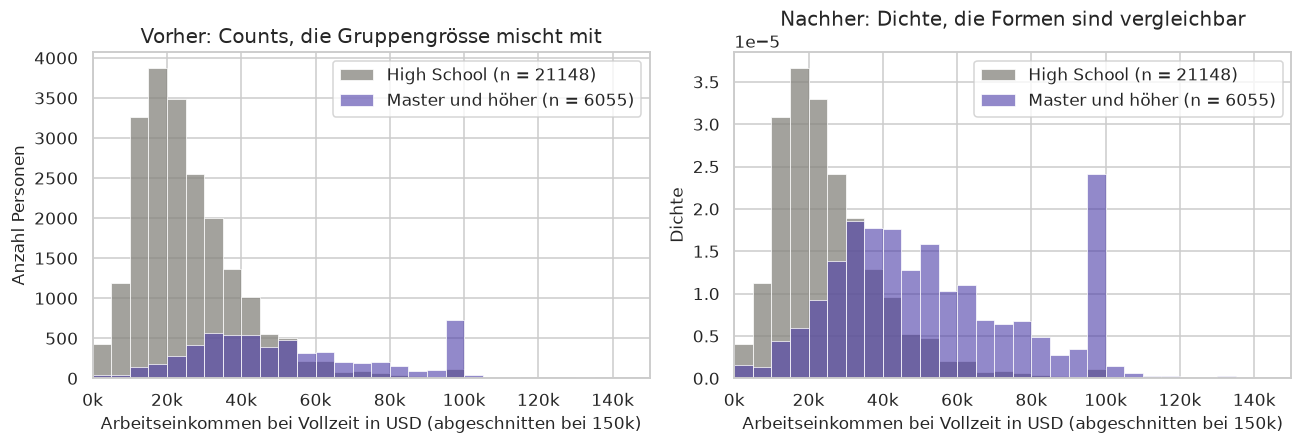

In [7]:
fig, achsen = plt.subplots(1, 2, figsize=(12, 4.2))
for ax, stat, titel in [
    (achsen[0], "count", "Vorher: Counts, die Gruppengrösse mischt mit"),
    (achsen[1], "density", "Nachher: Dichte, die Formen sind vergleichbar"),
]:
    sns.histplot(x=hs, bins=kanten, stat=stat, color=FARBE_VORHER, label=f"High School (n = {len(hs)})", ax=ax)
    sns.histplot(x=master, bins=kanten, stat=stat, color=FARBE_NACHHER, alpha=0.6,
                 label=f"Master und höher (n = {len(master)})", ax=ax)
    ax.set(title=titel, xlim=(0, 150000), xlabel="Arbeitseinkommen bei Vollzeit in USD (abgeschnitten bei 150k)")
    ax.xaxis.set_major_formatter(lambda x, pos: f"{x / 1000:.0f}k")
    ax.legend(loc="upper right")
achsen[0].set_ylabel("Anzahl Personen")
achsen[1].set_ylabel("Dichte")
plt.tight_layout()
plt.show()

**Erkenntnis:**
- Links bestimmt vor allem die Gruppengrösse das Bild: Die Master-Gruppe wirkt klein und flach.
- Rechts ist jede Gruppe für sich normiert, beide Flächen sind 1. Jetzt sieht man die Formen: Die High-School-Einkommen liegen eng um 20'000 USD, die Master-Einkommen sind breiter verteilt und liegen weiter rechts.
- Von den Anteilen her bleibt vom Faktor 12 noch ein Faktor 3.6: 16.5 % der High-School-Gruppe liegen in der Klasse von 20'000 bis 25'000 USD, aber nur 4.6 % der Master-Gruppe.
- Der hohe Balken bei 100'000 USD in der Master-Gruppe ist das Top-Coding bei 99'999 USD und kein zweiter Gipfel.
- Die Dichte selbst ist kein Anteil (hier Werte um 0.00003 pro USD). Erst Dichte mal Klassenbreite ergibt den Anteil. Die y-Achse liest man deshalb nur im Vergleich.

### 1.2 Binregeln: Sturges, Wurzel, Freedman-Diaconis

Für die 63'186 Arbeitseinkommen schlägt Sturges 17 Klassen vor, die Wurzelregel 252 und Freedman-Diaconis 260. Welches Histogramm zeigt die Form der Einkommen?

In [8]:
n = len(lohn_vollzeit)
q1, q3 = lohn_vollzeit.quantile([0.25, 0.75])
iqr = q3 - q1
spannweite = lohn_vollzeit.max() - lohn_vollzeit.min()

bins_sturges = int(np.ceil(np.log2(n) + 1))
bins_wurzel = int(np.ceil(np.sqrt(n)))
h_fd = 2 * iqr / np.cbrt(n)
bins_fd = int(np.ceil(spannweite / h_fd))

print(f"n = {n}, IQR = {zahl(iqr)} USD, Spannweite = {zahl(spannweite)} USD")
print(f"Sturges:           {bins_sturges:3d} Klassen, Breite {zahl(spannweite / bins_sturges)} USD")
print(f"Wurzelregel:       {bins_wurzel:3d} Klassen, Breite {zahl(spannweite / bins_wurzel)} USD")
print(f"Freedman-Diaconis: {bins_fd:3d} Klassen, Breite h = {zahl(h_fd)} USD")
print(f"Kontrolle mit NumPy (bins='fd'): {len(np.histogram_bin_edges(lohn_vollzeit, bins='fd')) - 1} Klassen")

# Warum hat das feine Histogramm so viele Spitzen?
print(f"\nAnteil der Einkommen, die auf 1'000 USD gerundet sind: {(lohn_vollzeit % 1000 == 0).mean():.1%}")
print(f"Anteil der Einkommen, die auf 5'000 USD gerundet sind: {(lohn_vollzeit % 5000 == 0).mean():.1%}")
print("Häufigste Werte:")
print(lohn_vollzeit.value_counts().head(5))

n = 63186, IQR = 23'000 USD, Spannweite = 299'996 USD
Sturges:            17 Klassen, Breite 17'647 USD
Wurzelregel:       252 Klassen, Breite 1'190 USD
Freedman-Diaconis: 260 Klassen, Breite h = 1'155 USD
Kontrolle mit NumPy (bins='fd'): 260 Klassen

Anteil der Einkommen, die auf 1'000 USD gerundet sind: 70.1%
Anteil der Einkommen, die auf 5'000 USD gerundet sind: 28.0%
Häufigste Werte:
EARNINGS
30000.0    2199
20000.0    2116
25000.0    2015
40000.0    1724
35000.0    1644
Name: count, dtype: int64


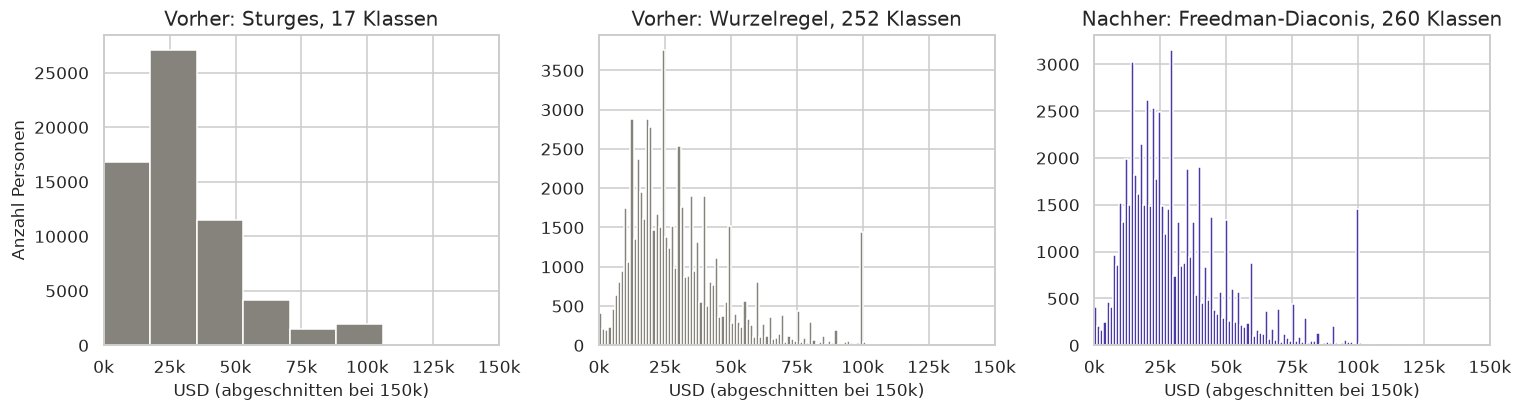

In [9]:
fig, achsen = plt.subplots(1, 3, figsize=(14, 3.9), sharex=True)
for ax, bins, titel, farbe in zip(
    achsen,
    [bins_sturges, bins_wurzel, bins_fd],
    [f"Vorher: Sturges, {bins_sturges} Klassen", f"Vorher: Wurzelregel, {bins_wurzel} Klassen",
     f"Nachher: Freedman-Diaconis, {bins_fd} Klassen"],
    [FARBE_VORHER, FARBE_VORHER, FARBE_NACHHER],
):
    ax.hist(lohn_vollzeit, bins=bins, color=farbe)
    ax.set(title=titel, xlabel="USD (abgeschnitten bei 150k)", xlim=(0, 150000))
    ax.xaxis.set_major_formatter(lambda x, pos: f"{x / 1000:.0f}k")
achsen[0].set_ylabel("Anzahl Personen")
plt.tight_layout()
plt.show()

**Erkenntnis:**
- Mit 17 Klassen (Breite rund 17'600 USD) bleibt nur ein grober Block: rechtsschief, mehr nicht. Sturges ist für normalnahe Daten gedacht und für unsere schiefe Verteilung mit über 60'000 Werten viel zu grob.
- Wurzelregel und Freedman-Diaconis ergeben fast dieselbe Klassenbreite (rund 1'200 USD). Dort sieht man viele einzelne Spitzen. Das sind keine Gipfel der Verteilung, sondern **Rundung**: 70.1 % der Befragten geben ihr Einkommen auf 1'000 USD genau an, 28.0 % sogar auf 5'000 USD. Die häufigsten Werte sind 30'000, 20'000 und 25'000 USD.
- Für unsere Einkommen ist FD die passende Regel, die Spitzen müssen wir aber als Rundung lesen. Für einen Überblick über die Form verwenden wir in den anderen Plots Klassen von 2'500 oder 5'000 USD.

### 1.3 KDE und die Bandbreite

`sns.kdeplot(lohn_vollzeit)` zeichnet eine glatte Kurve. Dahinter steckt die Bandbreite h: Die Scott-Regel ergibt 2'317 USD, die Silverman-Regel 1'693 USD. Welche Kurve beschreibt die Einkommen besser?

In [10]:
sd = lohn_vollzeit.std(ddof=1)
h_scott = sd / n ** 0.2
h_silverman = 0.9 * min(sd, iqr / 1.34) / n ** 0.2

print(f"SD = {zahl(sd)} USD, IQR / 1.34 = {zahl(iqr / 1.34)} USD -> Silverman nimmt den kleineren Wert")
print(f"Scott:     h = {zahl(h_scott)} USD")
print(f"Silverman: h = {zahl(h_silverman)} USD")
print(f"Verhältnis Silverman / Scott = {h_silverman / h_scott:.2f}")

SD = 21'137 USD, IQR / 1.34 = 17'164 USD -> Silverman nimmt den kleineren Wert
Scott:     h = 2'317 USD
Silverman: h = 1'693 USD
Verhältnis Silverman / Scott = 0.73


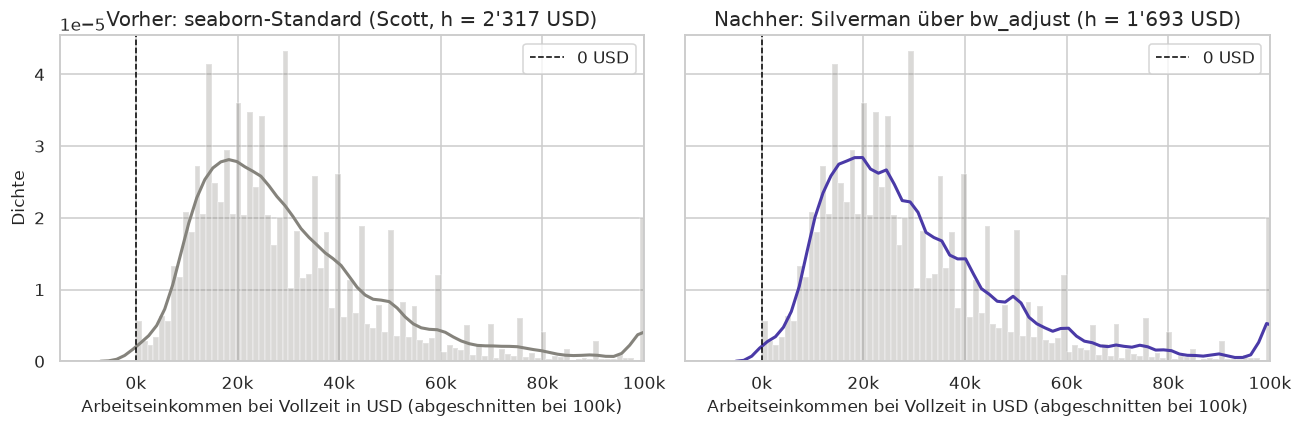

In [11]:
kanten_fd = np.histogram_bin_edges(lohn_vollzeit, bins="fd")
fig, achsen = plt.subplots(1, 2, figsize=(12, 4.2), sharey=True)
# seaborn verwendet standardmässig die Scott-Regel. bw_method="silverman" rechnet in seaborn eine andere Variante
# als die Formel aus der Vorlesung, deshalb setzen wir die Silverman-Bandbreite über den Faktor bw_adjust.
for ax, faktor, titel, farbe in zip(
    achsen,
    [1.0, h_silverman / h_scott],
    [f"Vorher: seaborn-Standard (Scott, h = {zahl(h_scott)} USD)",
     f"Nachher: Silverman über bw_adjust (h = {zahl(h_silverman)} USD)"],
    [FARBE_VORHER, FARBE_NACHHER],
):
    ax.hist(lohn_vollzeit, bins=kanten_fd, density=True, color=FARBE_VORHER, alpha=0.3)
    sns.kdeplot(lohn_vollzeit, bw_adjust=faktor, color=farbe, linewidth=2, ax=ax)
    ax.axvline(0, color="black", linestyle="--", linewidth=1, label="0 USD")
    ax.set(title=titel, xlim=(-15000, 100000), xlabel="Arbeitseinkommen bei Vollzeit in USD (abgeschnitten bei 100k)")
    ax.xaxis.set_major_formatter(lambda x, pos: f"{x / 1000:.0f}k")
    ax.legend(loc="upper right")
achsen[0].set_ylabel("Dichte")
plt.tight_layout()
plt.show()

**Erkenntnis:**
- Die SD ist durch die lange rechte Flanke grösser als die robuste Streuung (21'137 gegen 17'164 USD). Silverman nimmt deshalb den IQR, und die Bandbreite wird um gut ein Viertel schmaler.
- Die schmalere Silverman-Kurve folgt aber vor allem den Rundungsspitzen aus 1.2 und wird wellig. Die Wellen bei 30'000, 40'000 oder 50'000 USD sind keine echten Gipfel. Die Scott-Kurve glättet sie weg und zeigt die Form klarer: ein Gipfel um 20'000 USD und eine lange rechte Flanke.
- Beide Kurven legen etwas Dichte unter 0 USD, obwohl alle Einkommen positiv sind. Die Glocken der KDE laufen über den Rand der Daten hinaus.
- Ganz rechts steigen beide Kurven wieder an. Dort beginnt die Spitze des Top-Codings bei 100'000 USD.
- Bei unseren gerundeten Einkommen ist deshalb der seaborn-Standard (Scott) die bessere Wahl.

### 1.4 Binzahl und Bandbreite entscheiden

Wie viele Gipfel hat die Altersverteilung aller 199'523 Personen? Mit `bw_adjust=2.0` zeigt die KDE zwei Gipfel, mit 0.5 fünf. Welche Aussage dürfen wir berichten?

In [12]:
alter = census["AGE"]
q1_a, q3_a = alter.quantile([0.25, 0.75])
print(f"n = {len(alter)}, Alter von {alter.min()} bis {alter.max()} Jahren")
print(f"Freedman-Diaconis: Klassenbreite h = {2 * (q3_a - q1_a) / np.cbrt(len(alter)):.2f} Jahre")
print("Das Alter ist in ganzen Jahren erfasst, deshalb nehmen wir Klassen von genau 1 Jahr.")

# Moden zählen statt behaupten: KDE auf einem Gitter ausrechnen und die lokalen Maxima suchen
werte = alter.to_numpy(dtype=float)
h_scott_alter = werte.std(ddof=1) / len(werte) ** 0.2
gitter = np.linspace(-5, 95, 401)

zeilen = []
for faktor in [0.5, 1.0, 2.0]:
    h = faktor * h_scott_alter
    dichte = np.zeros(len(gitter))
    for i in range(len(gitter)):
        z = (gitter[i] - werte) / h
        dichte[i] = np.exp(-0.5 * z ** 2).sum() / (len(werte) * h * np.sqrt(2 * np.pi))
    # lokales Maximum: höher als der linke und der rechte Nachbar
    moden = [round(gitter[i]) for i in range(1, len(gitter) - 1) if dichte[i] > dichte[i - 1] and dichte[i] > dichte[i + 1]]
    zeilen.append({"bw_adjust": faktor, "h (Jahre)": round(h, 2), "Anzahl Moden": len(moden), "Lage der Moden (Jahre)": moden})

pd.DataFrame(zeilen)

n = 199523, Alter von 0 bis 90 Jahren
Freedman-Diaconis: Klassenbreite h = 1.20 Jahre
Das Alter ist in ganzen Jahren erfasst, deshalb nehmen wir Klassen von genau 1 Jahr.


,bw_adjust,h (Jahre),Anzahl Moden,Lage der Moden (Jahre)
0,0.5,0.97,5,"[4, 24, 34, 64, 90]"
1,1.0,1.94,2,"[5, 34]"
2,2.0,3.89,2,"[8, 35]"


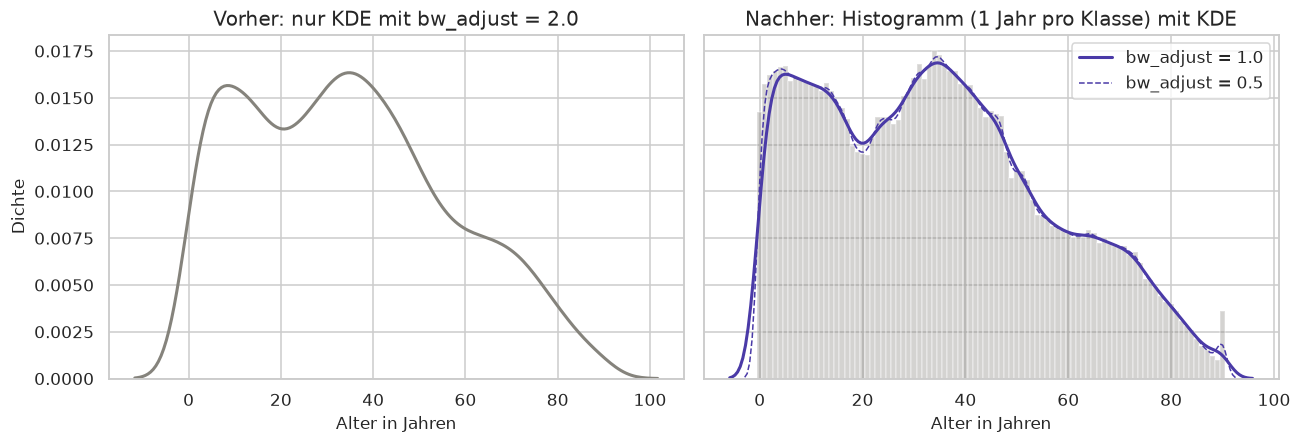

Personen mit Alter 90: 725, mit Alter 89: 195


In [13]:
klassen_alter = np.arange(-0.5, 91.5, 1)
fig, achsen = plt.subplots(1, 2, figsize=(12, 4.2), sharey=True)

sns.kdeplot(alter, bw_adjust=2.0, color=FARBE_VORHER, linewidth=2, ax=achsen[0])
achsen[0].set(title="Vorher: nur KDE mit bw_adjust = 2.0", xlabel="Alter in Jahren", ylabel="Dichte")

achsen[1].hist(alter, bins=klassen_alter, density=True, color=FARBE_VORHER, alpha=0.35)
sns.kdeplot(alter, bw_adjust=1.0, color=FARBE_NACHHER, linewidth=2, label="bw_adjust = 1.0", ax=achsen[1])
sns.kdeplot(alter, bw_adjust=0.5, color=FARBE_NACHHER, linewidth=1, linestyle="--", label="bw_adjust = 0.5", ax=achsen[1])
achsen[1].set(title="Nachher: Histogramm (1 Jahr pro Klasse) mit KDE", xlabel="Alter in Jahren")
achsen[1].legend(loc="upper right")
plt.tight_layout()
plt.show()
print(f"Personen mit Alter 90: {(alter == 90).sum()}, mit Alter 89: {(alter == 89).sum()}")

**Erkenntnis:**
- FD würde Klassen von 1.2 Jahren vorschlagen. Weil das Alter in ganzen Jahren erfasst ist, enthielten manche Klassen dann zwei Jahrgänge und andere nur einen. Klassen von genau 1 Jahr sind hier die sinnvolle Wahl.
- Zwei Gipfel bleiben bei allen drei Bandbreiten stabil: Kinder um 5 Jahre und die Jahrgänge des Babybooms um 34 Jahre. Dazwischen liegt eine Senke um 20 Jahre. Das ist echte Struktur.
- Nur bei 0.5 kommen drei Gipfel dazu. Die bei 24 und 64 Jahren sind kleine Wellen und kein belastbarer Befund. Der Gipfel bei 90 hat dagegen einen Grund in den Daten: Alle Personen ab 90 sind mit 90 erfasst (725 Personen mit 90, nur 195 mit 89). Das ist Top-Coding beim Alter.
- Die KDE mit 2.0 legt Dichte unter 0 und über 90 Jahre, die es nicht gibt.
- Unser Satz für den Bericht: "Histogramm mit 1 Jahr pro Klasse und KDE mit bw_adjust=1.0; die zwei Gipfel um 5 und 34 Jahre erscheinen bei 0.5, 1.0 und 2.0."

> **Fazit Histogramm und KDE**
>
> 1. Gruppen unterschiedlicher Grösse vergleichen wir mit der **Dichte** und schreiben n je Gruppe dazu.
> 2. Die **Klassenzahl** steuert die Aussage. Bei unseren gerundeten Einkommen zeigen feine Klassen vor allem Rundungsspitzen.
> 3. Die **Bandbreite** der KDE ist eine Wahl. Wir prüfen `bw_adjust` 0.5, 1.0 und 2.0 und berichten nur, was stabil bleibt.

---

## 2. Boxplot und Violinplot

Wie vergleicht man Gruppen, ohne zu viel in die Grafik hineinzulesen? Wir drehen an den Stellschrauben des Boxplots und prüfen, wann eine Violine mehr zeigt.

### 2.1 Zaunbreite und showfliers

Im Boxplot der Arbeitseinkommen nach Bildungsgruppe markiert die 1.5·IQR-Regel über 2'000 Punkte, über den Whiskern entsteht eine dichte Punktwolke. Sollen wir die Regel wechseln (`whis`), die Punkte ausblenden (`showfliers=False`) oder beides lassen?

In [14]:
markiert_tukey, markiert_perzentil = 0, 0
for gruppe in REIHENFOLGE:
    werte = lohn_vollzeit[bildungsgruppe == gruppe]
    q1_g, q3_g = werte.quantile([0.25, 0.75])
    p5, p95 = werte.quantile([0.05, 0.95])
    markiert_tukey += ((werte < q1_g - 1.5 * (q3_g - q1_g)) | (werte > q3_g + 1.5 * (q3_g - q1_g))).sum()
    markiert_perzentil += ((werte < p5) | (werte > p95)).sum()

print(f"Tukey (whis=1.5) je Bildungsgruppe:       {markiert_tukey} von {n} markiert ({markiert_tukey / n:.1%})")
print(f"Perzentile (whis=[5, 95]) je Gruppe:      {markiert_perzentil} von {n} ausserhalb ({markiert_perzentil / n:.1%})")

# Auch bei einer fast symmetrischen Variable markiert Tukey Werte: das Alter der Vollzeit-Erwerbstätigen
alter_vz = vollzeit["AGE"]
q1_v, q3_v = alter_vz.quantile([0.25, 0.75])
markiert_alter = ((alter_vz < q1_v - 1.5 * (q3_v - q1_v)) | (alter_vz > q3_v + 1.5 * (q3_v - q1_v))).sum()
print(f"\nAlter der Vollzeit-Erwerbstätigen: Zäune {q1_v - 1.5 * (q3_v - q1_v):.1f} bis {q3_v + 1.5 * (q3_v - q1_v):.1f} Jahre, "
      f"markiert {markiert_alter} von {len(alter_vz)} ({markiert_alter / len(alter_vz):.2%})")

Tukey (whis=1.5) je Bildungsgruppe:       2443 von 63186 markiert (3.9%)
Perzentile (whis=[5, 95]) je Gruppe:      5874 von 63186 ausserhalb (9.3%)

Alter der Vollzeit-Erwerbstätigen: Zäune 5.5 bis 73.5 Jahre, markiert 199 von 63186 (0.31%)


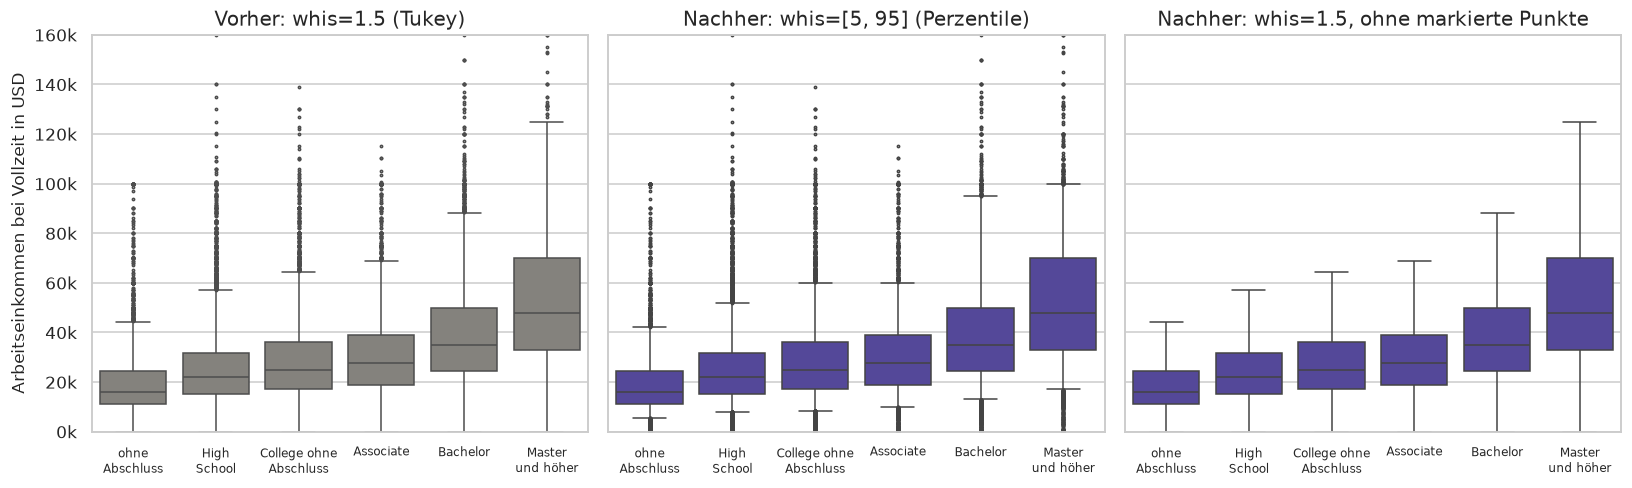

Achse bei 160k abgeschnitten, 45 Werte liegen darüber.


In [15]:
fig, achsen = plt.subplots(1, 3, figsize=(15, 4.6), sharey=True)
einstellungen = [
    ({"whis": 1.5}, "Vorher: whis=1.5 (Tukey)", FARBE_VORHER),
    ({"whis": [5, 95]}, "Nachher: whis=[5, 95] (Perzentile)", FARBE_NACHHER),
    ({"whis": 1.5, "showfliers": False}, "Nachher: whis=1.5, ohne markierte Punkte", FARBE_NACHHER),
]
for ax, (optionen, titel, farbe) in zip(achsen, einstellungen):
    sns.boxplot(x=bildungsgruppe, y=lohn_vollzeit, order=REIHENFOLGE, color=farbe, fliersize=1.5, ax=ax, **optionen)
    ax.set_xticks(range(len(REIHENFOLGE)), KURZ, fontsize=8)
    ax.set(title=titel, xlabel=None)
achsen[0].set(ylabel="Arbeitseinkommen bei Vollzeit in USD", ylim=(0, 160000))
achsen[0].yaxis.set_major_formatter(lambda y, pos: f"{y / 1000:.0f}k")
plt.tight_layout()
plt.show()
print(f"Achse bei 160k abgeschnitten, {(lohn_vollzeit > 160000).sum()} Werte liegen darüber.")

**Erkenntnis:**
- Mit Tukey-Zäunen je Bildungsgruppe sind 2'443 Werte markiert (3.9 %), alle über dem oberen Zaun. Mit `whis=[5, 95]` liegen per Definition rund 10 % ausserhalb (9.3 %, etwas weniger wegen der vielen gleichen, gerundeten Werte an den Grenzen). Das sind dann einfach die Ränder der Verteilung und keine Kandidaten. Neu erscheinen auch unten Punkte.
- Auch bei einer fast symmetrischen Variable markiert Tukey Werte: Beim Alter der Vollzeit-Erwerbstätigen sind es 199 Personen (0.31 %), alle älter als 73.5 Jahre. Markiert heisst also nicht falsch.
- Ohne die Punkte (rechts) ist der Vergleich der Boxen ruhiger. Das ist zulässig, aber nur mit dem Hinweis, dass 2'443 Punkte ausgeblendet sind.
- Für unseren Bericht nehmen wir `whis=1.5` und zeigen die Punkte, weil die lange rechte Flanke zur Aussage gehört.

### 2.2 Notch: Unsicherheitsbereich des Medians

Im Verkauf verdienen Frauen bei Vollzeit im Median 18'491 USD, Männer 32'500 USD. In den Haushaltsdiensten (z.B. Haushaltshilfen und Kinderbetreuung in Privathaushalten) sind es 9'100 USD gegen 11'000 USD. Welcher der beiden Unterschiede ist belastbar?

In [16]:
GESCHLECHT = {"Female": "Frauen", "Male": "Männer"}
BERUFE = {"Sales": "Verkauf", "Private household services": "Haushaltsdienste"}
vergleich = vollzeit[vollzeit["MAJOR_OCCUPATION"].isin(BERUFE)].assign(
    BERUF=lambda d: d["MAJOR_OCCUPATION"].astype(str).map(BERUFE),
    GESCHLECHT=lambda d: d["SEX"].astype(str).map(GESCHLECHT),
)

tabelle = vergleich.groupby(["BERUF", "GESCHLECHT"])["EARNINGS"].agg(
    n="size", median="median", iqr=lambda s: s.quantile(0.75) - s.quantile(0.25))
# So rechnet matplotlib die Kerbe: Median ± 1.57 · IQR / Wurzel(n)
tabelle["kerbe_von"] = tabelle["median"] - 1.57 * tabelle["iqr"] / np.sqrt(tabelle["n"])
tabelle["kerbe_bis"] = tabelle["median"] + 1.57 * tabelle["iqr"] / np.sqrt(tabelle["n"])
tabelle.round(0)

n   median      iqr  kerbe_von  kerbe_bis
BERUF            GESCHLECHT                                              
Haushaltsdienste Frauen       171   9100.0   8800.0     8043.0    10157.0
                 Männer         9  11000.0   7500.0     7075.0    14925.0
Verkauf          Frauen      2576  18491.0  18000.0    17934.0    19048.0
                 Männer      4260  32500.0  30000.0    31778.0    33222.0

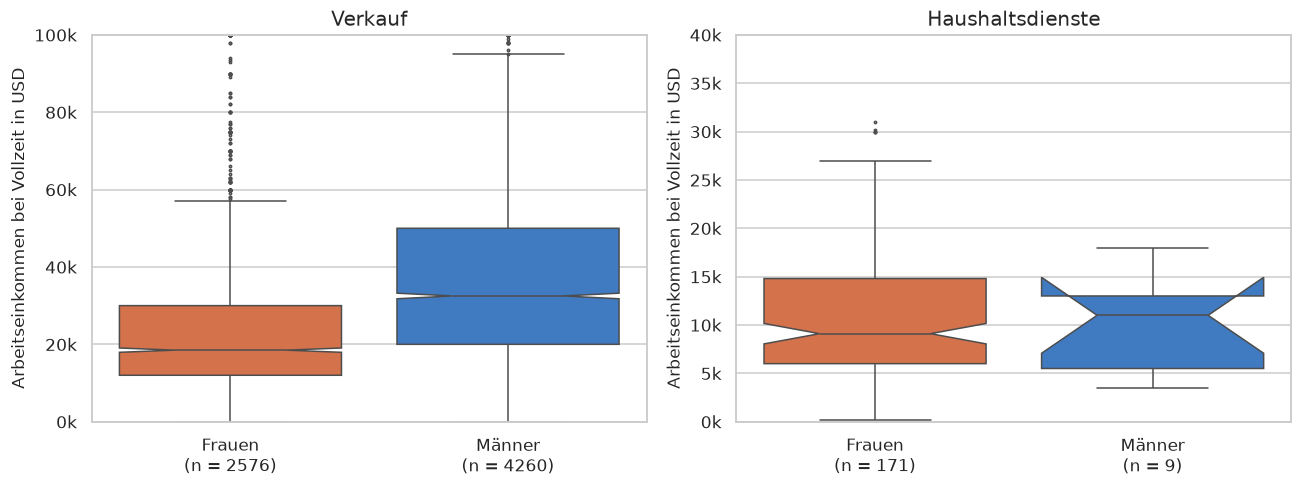

In [17]:
fig, achsen = plt.subplots(1, 2, figsize=(12, 4.6))
for ax, beruf in zip(achsen, ["Verkauf", "Haushaltsdienste"]):
    daten = vergleich[vergleich["BERUF"] == beruf]
    sns.boxplot(data=daten, x="GESCHLECHT", y="EARNINGS", order=["Frauen", "Männer"], hue="GESCHLECHT",
                palette={"Frauen": FARBE_FRAUEN, "Männer": FARBE_MAENNER}, notch=True, fliersize=1.5, legend=False, ax=ax)
    n_je = daten["GESCHLECHT"].value_counts()
    ax.set_xticks(range(2), [f"Frauen\n(n = {n_je['Frauen']})", f"Männer\n(n = {n_je['Männer']})"])
    ax.set(title=beruf, xlabel=None, ylabel="Arbeitseinkommen bei Vollzeit in USD")
    ax.yaxis.set_major_formatter(lambda y, pos: f"{y / 1000:.0f}k")
achsen[0].set_ylim(0, 100000)
achsen[1].set_ylim(0, 40000)
plt.tight_layout()
plt.show()

**Erkenntnis:**
- Im Verkauf liegen die Kerben weit auseinander (Frauen bis 19'048 USD, Männer ab 31'778 USD). Der Unterschied von 14'009 USD ist ein starker Hinweis auf einen echten Lageunterschied. Bei mehreren tausend Personen pro Gruppe sind die Kerben so schmal, dass sie kaum auffallen.
- In den Haushaltsdiensten gibt es nur 9 Männer. Ihre Kerbe reicht von 7'075 bis 14'925 USD und ist breiter als die Box, deshalb klappt sie über die Box hinaus. Sie überlappt deutlich mit der Kerbe der Frauen. Den Unterschied von 1'900 USD dürfen wir nicht behaupten.
- Die Kerbe ist eine Faustregel, kein Test. Bei unseren grossen Gruppen ist sie fast immer getrennt, nützlich wird sie bei kleinen Untergruppen.

### 2.3 Linear oder Log?

Bei den Personen ab 25 Jahren liegt das Gesamteinkommen im Median bei 16'854 USD, das Maximum bei 347'998 USD, also beim 20.6-Fachen. Auf der linearen Achse werden die Boxen der Bildungsgruppen dadurch flach gedrückt. Dazu kommen 5'339 Personen ohne Einkommen und 538 mit negativem Einkommen. Wie zeigen wir das lesbar?

In [18]:
ab25 = census[census["AGE"] >= 25].assign(
    BILDUNGSGRUPPE=lambda d: d["EDUCATION"].astype(str).map(BILDUNGSGRUPPEN).fillna("ohne Abschluss"))
eink25 = ab25["TOTAL_INCOME"].dropna()
print(f"Personen ab 25 mit Einkommen: n = {len(eink25)}")
print(f"Median {zahl(eink25.median())} USD, Maximum {zahl(eink25.max())} USD, Verhältnis {eink25.max() / eink25.median():.1f}")
print(f"Einkommen genau 0: {(eink25 == 0).sum()}, negativ: {(eink25 < 0).sum()}")

positiv = ab25[ab25["TOTAL_INCOME"] > 0]
print(f"\nFür die Log-Skala ausgeschlossen: {len(eink25) - len(positiv)} Werte <= 0, es bleiben n = {len(positiv)}")
print("\nMedian je Bildungsgruppe (nur Einkommen > 0):")
print(positiv.groupby("BILDUNGSGRUPPE")["TOTAL_INCOME"].median().reindex(REIHENFOLGE))

Personen ab 25 mit Einkommen: n = 125564
Median 16'854 USD, Maximum 347'998 USD, Verhältnis 20.6
Einkommen genau 0: 5339, negativ: 538

Für die Log-Skala ausgeschlossen: 5877 Werte <= 0, es bleiben n = 119687

Median je Bildungsgruppe (nur Einkommen > 0):
BILDUNGSGRUPPE
ohne Abschluss             9229.0
High School               15580.0
College ohne Abschluss    19892.0
Associate                 22895.0
Bachelor                  30000.0
Master und höher          41000.0
Name: TOTAL_INCOME, dtype: float64


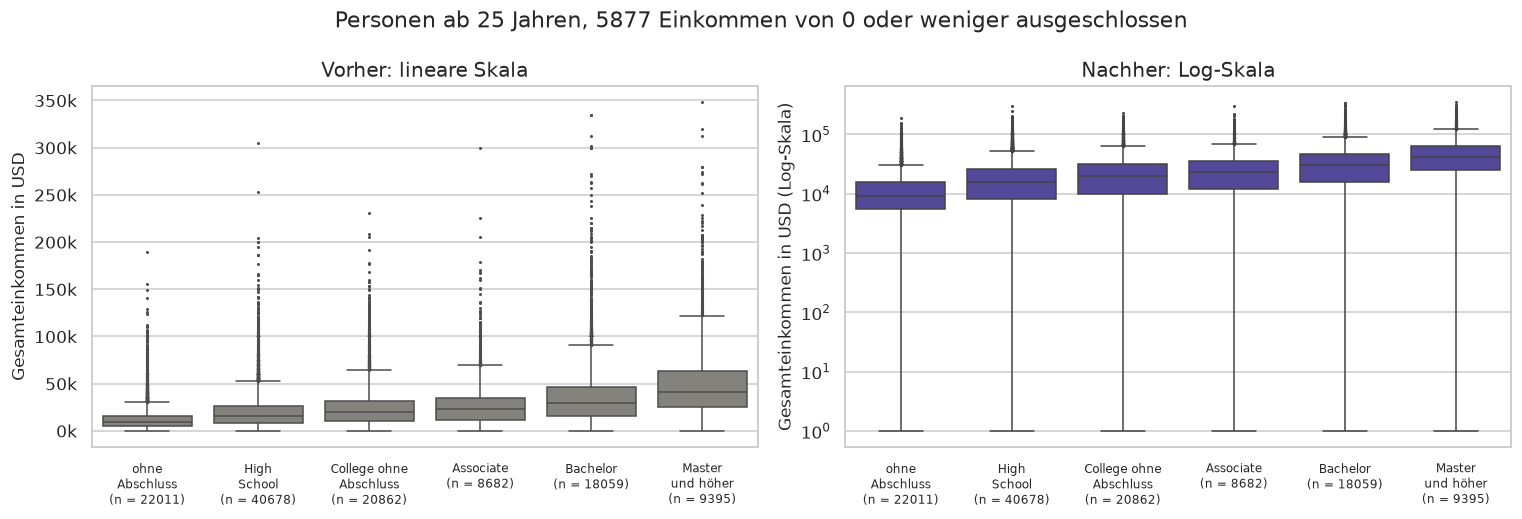

In [19]:
n_je_gruppe = positiv["BILDUNGSGRUPPE"].value_counts()
beschriftung = [f"{kurz}\n(n = {n_je_gruppe[g]})" for g, kurz in zip(REIHENFOLGE, KURZ)]
anzahl_ohne = len(eink25) - len(positiv)
fig, achsen = plt.subplots(1, 2, figsize=(14, 4.8))
for ax, log_skala, titel, farbe in zip(achsen, [False, True], ["Vorher: lineare Skala", "Nachher: Log-Skala"],
                                       [FARBE_VORHER, FARBE_NACHHER]):
    sns.boxplot(data=positiv, x="BILDUNGSGRUPPE", y="TOTAL_INCOME", order=REIHENFOLGE, color=farbe, fliersize=1, ax=ax)
    ax.set_xticks(range(len(REIHENFOLGE)), beschriftung, fontsize=8)
    ax.set(title=titel, xlabel=None)
    if log_skala:
        ax.set_yscale("log")
        ax.set_ylabel("Gesamteinkommen in USD (Log-Skala)")
    else:
        ax.set_ylabel("Gesamteinkommen in USD")
        ax.yaxis.set_major_formatter(lambda y, pos: f"{y / 1000:.0f}k")
fig.suptitle(f"Personen ab 25 Jahren, {anzahl_ohne} Einkommen von 0 oder weniger ausgeschlossen")
plt.tight_layout()
plt.show()

**Erkenntnis:**
- Links bestimmen die wenigen sehr hohen Einkommen die Achse. Die Boxen liegen alle im untersten Fünftel der Grafik, die Unterschiede zwischen den Gruppen sind kaum zu lesen.
- Auf der Log-Skala stehen gleiche Verhältnisse gleich weit auseinander. Jetzt sieht man die Stufen klar: Der Median steigt von 9'229 USD ohne Abschluss über 15'580 USD (High School) bis 41'000 USD bei Master und höher.
- Die Log-Skala verlangt positive Werte. Die 5'877 Einkommen von 0 oder weniger haben wir ausgeschlossen und das in der Grafik vermerkt. Die Kennzahlen ändern sich durch die Log-Achse nicht, nur die Darstellung.
- Die unteren Whisker reichen bis 1 USD: Auch beim Gesamteinkommen gibt es Werte von genau 1 USD (237 Personen ab 25). Mehr dazu in 4.2.

### 2.4 Box oder Violine?

Bei den 15- bis 24-Jährigen zeigt der Boxplot der Arbeitswochen eine Box von 0 bis 52 Wochen mit Median 15. Das sieht nach einer breiten Streuung über das ganze Jahr aus. Stimmt das?

In [20]:
wochen = ab15["WEEKS_WORKED"]
altersgruppe = pd.cut(ab15["AGE"], bins=[14, 24, 64, 90], labels=["15-24", "25-64", "65+"])
wochen.groupby(altersgruppe, observed=True).describe()[["count", "min", "25%", "50%", "75%", "max"]]

,count,min,25%,50%,75%,max
AGE,,,,,,
15-24,26394.0,0.0,0.0,15.0,52.0,52.0
25-64,101418.0,0.0,26.0,52.0,52.0,52.0
65+,24289.0,0.0,0.0,0.0,0.0,52.0


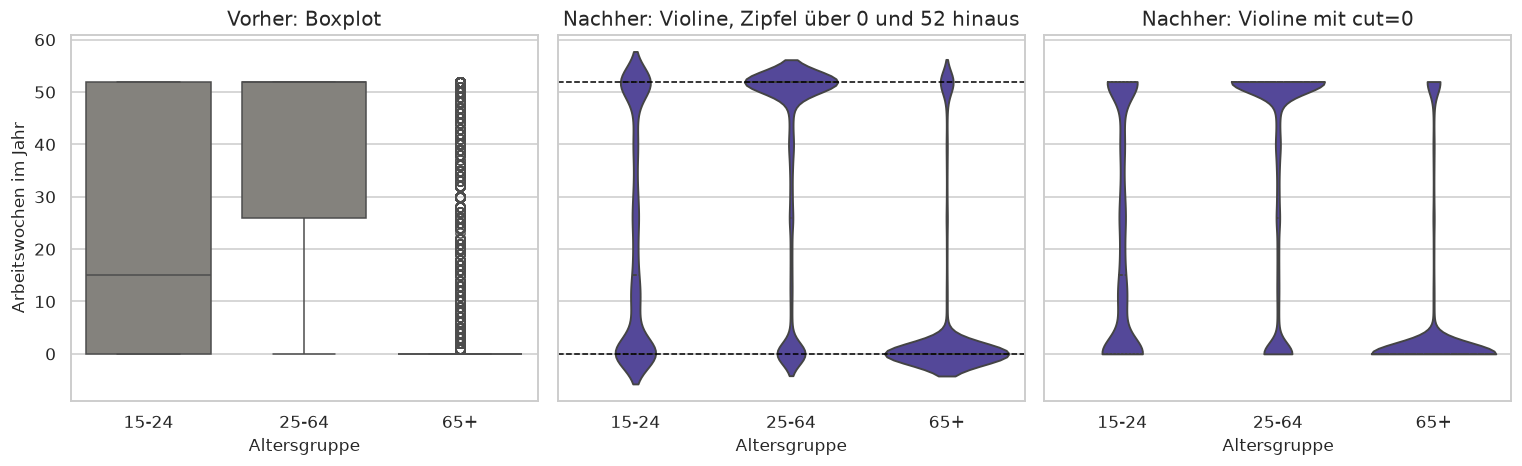

In [21]:
fig, achsen = plt.subplots(1, 3, figsize=(14, 4.4), sharey=True)
sns.boxplot(x=altersgruppe, y=wochen, color=FARBE_VORHER, ax=achsen[0])
achsen[0].set(title="Vorher: Boxplot", xlabel="Altersgruppe", ylabel="Arbeitswochen im Jahr")
sns.violinplot(x=altersgruppe, y=wochen, color=FARBE_NACHHER, inner="quartile", ax=achsen[1])
achsen[1].axhline(0, color="black", linestyle="--", linewidth=1)
achsen[1].axhline(52, color="black", linestyle="--", linewidth=1)
achsen[1].set(title="Nachher: Violine, Zipfel über 0 und 52 hinaus", xlabel="Altersgruppe")
sns.violinplot(x=altersgruppe, y=wochen, color=FARBE_NACHHER, inner="quartile", cut=0, ax=achsen[2])
achsen[2].set(title="Nachher: Violine mit cut=0", xlabel="Altersgruppe")
plt.tight_layout()
plt.show()

**Erkenntnis:**
- Die Violine zeigt, was die Box verdeckt: Bei den 15- bis 24-Jährigen gibt es zwei Gipfel, bei 0 und bei 52 Wochen, und dazwischen nur wenige Personen. Der Median von 15 Wochen liegt in einem Bereich, in dem kaum jemand ist.
- Bei den 25- bis 64-Jährigen reicht die Box von 26 bis 52 Wochen, Median und Q3 liegen beide bei 52. Der zweite, kleinere Gipfel bei 0 erscheint in der Box nur als langer Whisker. Bei 65+ ist die Box ein Strich bei 0, und alle, die gearbeitet haben, erscheinen als markierte Punkte.
- Die Standard-Violine hat Zipfel unter 0 und über 52 Wochen, die es nicht geben kann. Mit `cut=0` endet sie an den beobachteten Werten.
- Für die Arbeitswochen ist die Violine mit `cut=0` deshalb die bessere Darstellung. Bei so grossen Gruppen ist die KDE dahinter verlässlich.

> **Fazit Box und Violine**
>
> 1. **`whis`** ist eine Wahl: Tukey markiert Kandidaten, Perzentil-Whisker markieren immer rund 10 %. `showfliers=False` nur mit Hinweis, wie viele Punkte fehlen.
> 2. Die **Kerbe** hilft nur bei kleinen Gruppen. Bei unseren grossen Gruppen ist sie fast unsichtbar, bei sehr kleinen klappt sie über die Box.
> 3. Für unsere rechtsschiefen Einkommen ist die **Log-Skala** die lesbare Darstellung, mit Hinweis auf die ausgeschlossenen Werte.
> 4. Die **Violine** zeigt, was die Box verdeckt, zum Beispiel zwei Gipfel. Mit `cut=0` endet sie an den Daten.

---

## 3. ECDF und QQ-Plot

Passt eine Verteilung zu einer Referenz, und wie hält man die Entscheidung fest? Die ECDF vergleicht Gruppen ohne Klassenwahl, der QQ-Plot vergleicht die Form mit der Normalverteilung.

### 3.1 ECDF im Gruppenvergleich

Frauen erreichen beim Arbeitseinkommen die 50-%-Marke bei 21'840 USD, Männer erst bei 30'000 USD. Im ECDF-Plot liegt die Kurve der Männer trotzdem unten. Warum heisst unten hier mehr Einkommen?

In [22]:
geschlecht = vollzeit["SEX"].astype(str).map(GESCHLECHT)
tabelle = lohn_vollzeit.groupby(geschlecht).agg(
    n="size",
    median="median",
    P90=lambda s: s.quantile(0.9),
    anteil_bis_50k=lambda s: (s <= 50000).mean(),
)
tabelle.round(3)

,n,median,P90,anteil_bis_50k
SEX,,,,
Frauen,25789,21840.0,43000.0,0.944
Männer,37397,30000.0,65000.0,0.811


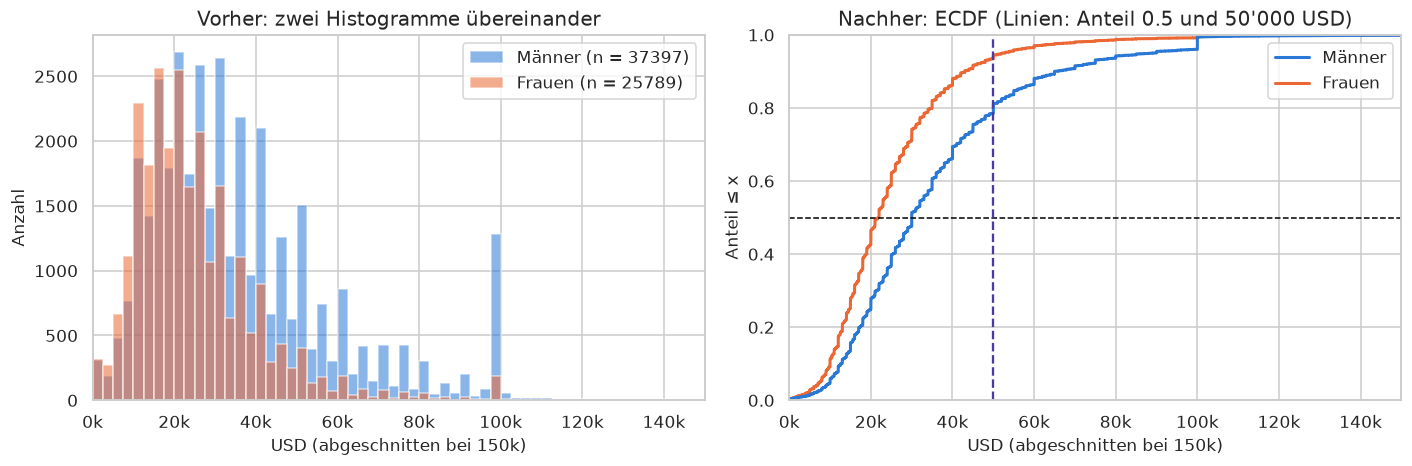

In [23]:
fig, achsen = plt.subplots(1, 2, figsize=(13, 4.4))
for name, farbe in [("Männer", FARBE_MAENNER), ("Frauen", FARBE_FRAUEN)]:
    achsen[0].hist(lohn_vollzeit[geschlecht == name], bins=np.arange(0, 150001, 2500), color=farbe, alpha=0.55,
                   label=f"{name} (n = {(geschlecht == name).sum()})")
achsen[0].set(title="Vorher: zwei Histogramme übereinander", xlabel="USD (abgeschnitten bei 150k)", ylabel="Anzahl")
achsen[0].legend(loc="upper right")

sns.ecdfplot(x=lohn_vollzeit, hue=geschlecht, palette={"Frauen": FARBE_FRAUEN, "Männer": FARBE_MAENNER},
             linewidth=2, ax=achsen[1])
achsen[1].axhline(0.5, color="black", linestyle="--", linewidth=1)
achsen[1].axvline(50000, color=FARBE_NACHHER, linestyle="--", linewidth=1.5)
achsen[1].set(title="Nachher: ECDF (Linien: Anteil 0.5 und 50'000 USD)", xlabel="USD (abgeschnitten bei 150k)",
              ylabel="Anteil ≤ x")
achsen[1].get_legend().set_title(None)
for ax in achsen:
    ax.set_xlim(0, 150000)
    ax.xaxis.set_major_formatter(lambda x, pos: f"{x / 1000:.0f}k")
plt.tight_layout()
plt.show()

**Erkenntnis:**
- Bei 50'000 USD haben die Frauen schon 94.4 % ihrer Werte erreicht, die Männer erst 81.1 %. Die Kurve der Männer steigt langsamer, weil ihre Einkommen weiter rechts liegen. **Unten heisst grösser.**
- Die Kurven kreuzen sich nicht: Bei jedem Betrag hat ein grösserer Anteil der Frauen höchstens so viel verdient. Die Verteilung der Männer ist also über den ganzen Bereich nach rechts verschoben, nicht nur im Median. Beim P90 ist der Abstand noch grösser (43'000 gegen 65'000 USD).
- Links muss man zwei überlagerte Histogramme mit verschiedenem n und einer Klassenwahl vergleichen. Die ECDF braucht keine Klassen. Der Sprung bei 100'000 USD zeigt auch hier das Top-Coding.
- Das ist ein beschreibender Befund für Vollzeit-Erwerbstätige. Ob Beruf, Bildung oder Arbeitsstunden den Abstand erklären, ist damit noch nicht beantwortet.

### 3.2 QQ-Plot von Hand

Der Stundenlohn ist rechtsschief (Mittelwert 9.78 USD, Median 8.00 USD). Auf der Log-Skala sieht das Histogramm fast symmetrisch aus, Mittelwert und Median liegen nah beieinander. Ist der Stundenlohn auf der Log-Skala also normalverteilt?

In [24]:
from statistics import NormalDist


def qq_punkte(werte):
    """Sortierte Daten gegen Quantile der Standardnormalverteilung, dazu eine Gerade durch die Q1/Q3-Punkte."""
    daten = np.sort(np.asarray(werte, dtype=float))
    p = (np.arange(1, len(daten) + 1) - 0.5) / len(daten)            # Anteile (i - 0.5) / n
    normal = np.array([NormalDist().inv_cdf(anteil) for anteil in p])  # Quantile der Normalverteilung
    q1_daten, q3_daten = np.quantile(daten, [0.25, 0.75])
    q1_ref, q3_ref = NormalDist().inv_cdf(0.25), NormalDist().inv_cdf(0.75)
    steigung = (q3_daten - q1_daten) / (q3_ref - q1_ref)
    achsenabschnitt = q1_daten - steigung * q1_ref
    return normal, daten, steigung, achsenabschnitt


log_lohn = np.log10(stundenlohn)
normal, daten, steigung, achsenabschnitt = qq_punkte(log_lohn)
print(f"n = {len(log_lohn)}")
print(f"Stundenlohn:         Mittelwert {stundenlohn.mean():.2f} USD, Median {stundenlohn.median():.2f} USD")
print(f"log10(Stundenlohn):  Mittelwert {log_lohn.mean():.3f}, Median {log_lohn.median():.3f}")
print(f"Steigung der Q1/Q3-Geraden: {steigung:.3f}, SD von log10(Stundenlohn): {log_lohn.std(ddof=1):.3f}")
print(f"Genau 4.25 USD (damaliger Mindestlohn): {(stundenlohn == 4.25).sum()}, weniger als 4.25 USD: {(stundenlohn < 4.25).sum()}")

n = 11304
Stundenlohn:         Mittelwert 9.78 USD, Median 8.00 USD
log10(Stundenlohn):  Mittelwert 0.928, Median 0.903
Steigung der Q1/Q3-Geraden: 0.231, SD von log10(Stundenlohn): 0.224
Genau 4.25 USD (damaliger Mindestlohn): 376, weniger als 4.25 USD: 316


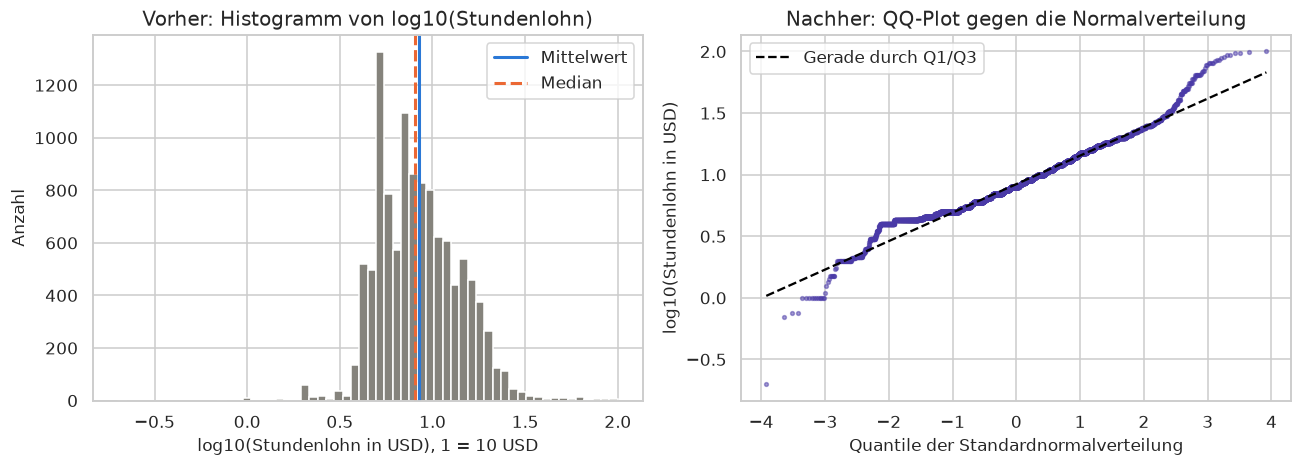

In [25]:
fig, achsen = plt.subplots(1, 2, figsize=(12, 4.4))
achsen[0].hist(log_lohn, bins=60, color=FARBE_VORHER)
achsen[0].axvline(log_lohn.mean(), color=FARBE_MITTELWERT, linewidth=2, label="Mittelwert")
achsen[0].axvline(log_lohn.median(), color=FARBE_MEDIAN, linewidth=2, linestyle="--", label="Median")
achsen[0].set(title="Vorher: Histogramm von log10(Stundenlohn)", xlabel="log10(Stundenlohn in USD), 1 = 10 USD",
              ylabel="Anzahl")
achsen[0].legend(loc="upper right")

achsen[1].scatter(normal, daten, s=6, color=FARBE_NACHHER, alpha=0.5)
achsen[1].plot(normal, achsenabschnitt + steigung * normal, color="black", linestyle="--", linewidth=1.5,
               label="Gerade durch Q1/Q3")
achsen[1].set(title="Nachher: QQ-Plot gegen die Normalverteilung", xlabel="Quantile der Standardnormalverteilung",
              ylabel="log10(Stundenlohn in USD)")
achsen[1].legend(loc="upper left")
plt.tight_layout()
plt.show()

**Erkenntnis:**
- In der Mitte liegen die Punkte auf der Geraden: Für den Grossteil der Werte ist log10(Stundenlohn) mit einer Normalverteilung verträglich. Die Steigung der Geraden (0.231) passt auch gut zur SD (0.224).
- Unten weicht der Plot mit einer waagrechten Stufe ab: 376 Personen verdienen genau 4.25 USD, das war damals der gesetzliche Mindestlohn in den USA. Darunter liegen noch 316 Personen mit tieferen Stundenlöhnen.
- Oben liegen die Punkte über der Geraden: Es gibt mehr sehr hohe Stundenlöhne, als die Normalverteilung erwarten lässt. Die kleineren Treppenstufen entstehen durch runde Löhne wie 5, 6 oder 8 USD.
- Auf der Log-Skala ist der Stundenlohn also in der Mitte fast normalverteilt, mit einer Untergrenze durch den Mindestlohn und einer schweren oberen Flanke. Das ist kein Beweis für Normalität, nur keine grosse Abweichung in der Mitte.

### 3.3 Bogen oder S-Kurve?

Arbeitseinkommen und Arbeitsstunden weichen beide sichtbar von einer Normalverteilung ab. Beim Einkommen liegt der Mittelwert weit über dem Median (31'306 gegen 26'000 USD), bei den Stunden liegen Mittelwert und Median nah beieinander (38.57 und 40). Welche Art von Abweichung haben die beiden?

In [26]:
arbeitsstunden = census.loc[census["HOURS_PER_WEEK"] > 0, "HOURS_PER_WEEK"]
print(f"Arbeitseinkommen: Mittelwert {zahl(lohn_vollzeit.mean())}, Median {zahl(lohn_vollzeit.median())} USD")
print(f"Arbeitsstunden:   Mittelwert {arbeitsstunden.mean():.2f}, Median {arbeitsstunden.median():.0f} Stunden, "
      f"genau 40 Stunden: {(arbeitsstunden == 40).mean():.1%}")
print(f"Arbeitsstunden unter 20: {(arbeitsstunden < 20).mean():.1%}, über 60: {(arbeitsstunden > 60).mean():.1%}")

qq_lohn = qq_punkte(lohn_vollzeit)
qq_stunden = qq_punkte(arbeitsstunden)

Arbeitseinkommen: Mittelwert 31'306, Median 26'000 USD
Arbeitsstunden:   Mittelwert 38.57, Median 40 Stunden, genau 40 Stunden: 45.3%
Arbeitsstunden unter 20: 8.0%, über 60: 2.8%


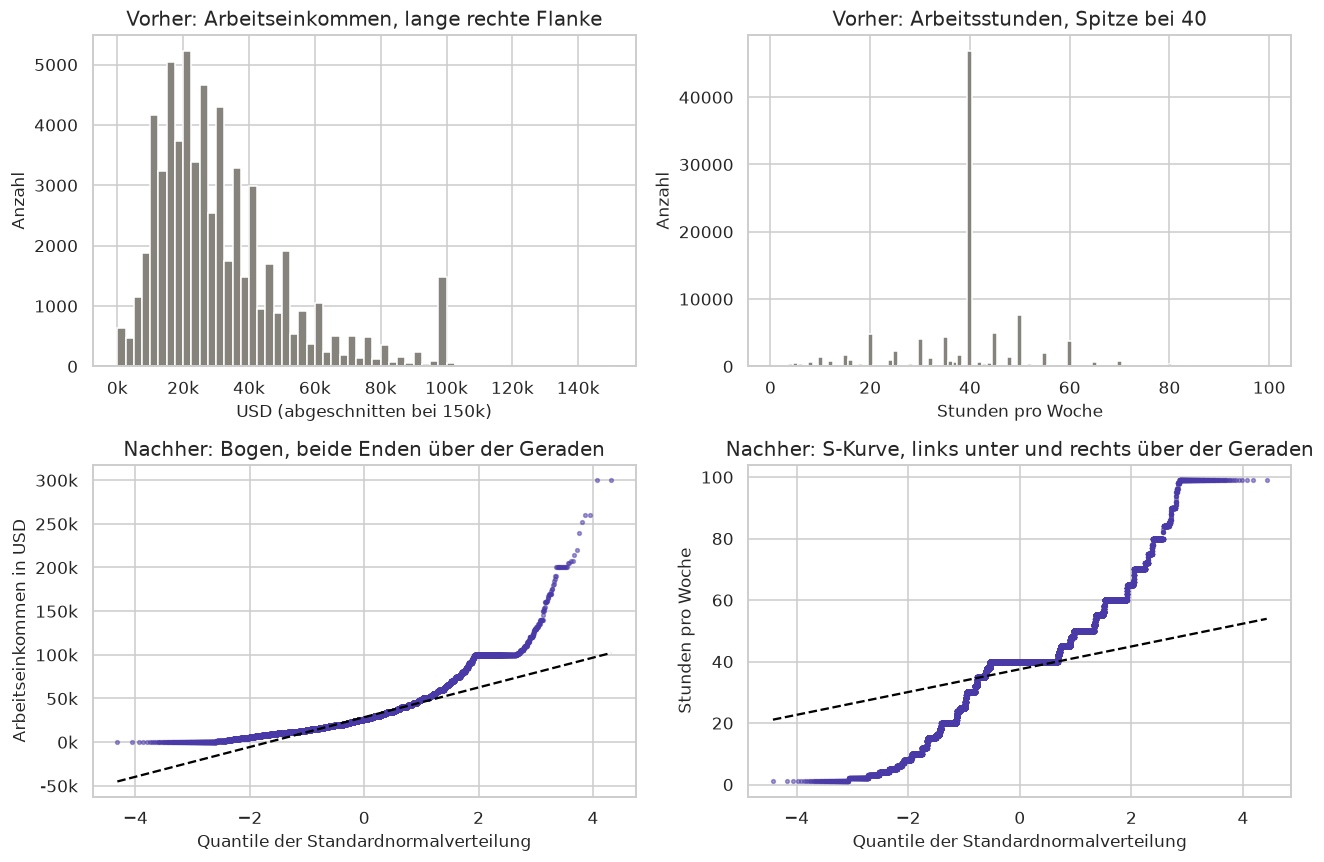

In [27]:
fig, achsen = plt.subplots(2, 2, figsize=(12, 8))
achsen[0, 0].hist(lohn_vollzeit, bins=np.arange(0, 150001, 2500), color=FARBE_VORHER)
achsen[0, 0].set(title="Vorher: Arbeitseinkommen, lange rechte Flanke", xlabel="USD (abgeschnitten bei 150k)",
                 ylabel="Anzahl")
achsen[0, 0].xaxis.set_major_formatter(lambda x, pos: f"{x / 1000:.0f}k")
achsen[0, 1].hist(arbeitsstunden, bins=np.arange(0.5, 100.5, 1), color=FARBE_VORHER)
achsen[0, 1].set(title="Vorher: Arbeitsstunden, Spitze bei 40", xlabel="Stunden pro Woche", ylabel="Anzahl")

for ax, (normal, daten, steigung, achsenabschnitt), titel, einheit in [
    (achsen[1, 0], qq_lohn, "Nachher: Bogen, beide Enden über der Geraden", "Arbeitseinkommen in USD"),
    (achsen[1, 1], qq_stunden, "Nachher: S-Kurve, links unter und rechts über der Geraden", "Stunden pro Woche"),
]:
    ax.scatter(normal, daten, s=6, color=FARBE_NACHHER, alpha=0.5)
    ax.plot(normal, achsenabschnitt + steigung * normal, color="black", linestyle="--", linewidth=1.5)
    ax.set(title=titel, xlabel="Quantile der Standardnormalverteilung", ylabel=einheit)
achsen[1, 0].yaxis.set_major_formatter(lambda y, pos: f"{y / 1000:.0f}k")
plt.tight_layout()
plt.show()

**Erkenntnis:**
- **Arbeitseinkommen: Bogen.** Beide Enden liegen über der Geraden. Unten bleiben die Einkommen bei 0 hängen, oben steigen sie viel stärker an, als die Normalverteilung erwarten lässt. Das ist Rechtsschiefe. Die waagrechte Stufe bei 100'000 USD und die einzelnen Punkte bei 200'000 und 300'000 USD sind das Top-Coding.
- **Arbeitsstunden: S-Kurve.** Links liegen die Punkte unter, rechts über der Geraden. Die Verteilung ist ungefähr symmetrisch um 40 Stunden, aber 45.3 % liegen genau bei 40. Dadurch ist die Mitte sehr schmal, und beide Ränder sind im Vergleich schwer: 8.0 % arbeiten weniger als 20 Stunden, 2.8 % mehr als 60. Die Stufe ganz oben entsteht, weil 99 für "99 Stunden und mehr" steht.
- Im Histogramm sehen beide einfach "auffällig" aus. Erst der QQ-Plot trennt Schiefe (Bogen) von schweren Rändern (S-Kurve). In beiden Fällen berichten wir robuste Kennzahlen.

### 3.4 Die Diagnose-Routine

Ein naiver Berichtssatz wäre: "Der durchschnittliche Stundenlohn beträgt 9.78 USD." Die Routine aus VL03 prüft in drei Schritten, ob dieser Satz trägt: ECDF mit Kennzahlen, Histogramm mit KDE, QQ-Plot. Am Ende steht ein Satz mit allen Parametern.

In [28]:
q1_s, median_s, q3_s = stundenlohn.quantile([0.25, 0.50, 0.75])
p90_s = stundenlohn.quantile(0.90)
oberer_zaun_s = q3_s + 1.5 * (q3_s - q1_s)
print(f"n = {len(stundenlohn)}, fehlend oder 0: {len(census) - len(stundenlohn)}")
print(f"Mittelwert {stundenlohn.mean():.2f} USD, Median {median_s:.2f} USD")
print(f"Q1 {q1_s:.2f} USD, Q3 {q3_s:.2f} USD, SD {stundenlohn.std(ddof=1):.2f} USD")
print(f"P90 {p90_s:.2f} USD")
print(f"Über dem oberen Tukey-Zaun ({oberer_zaun_s:.2f} USD): {(stundenlohn > oberer_zaun_s).sum()} Werte")

n = 11304, fehlend oder 0: 188219
Mittelwert 9.78 USD, Median 8.00 USD
Q1 5.85 USD, Q3 12.00 USD, SD 6.56 USD
P90 17.00 USD
Über dem oberen Tukey-Zaun (21.23 USD): 403 Werte


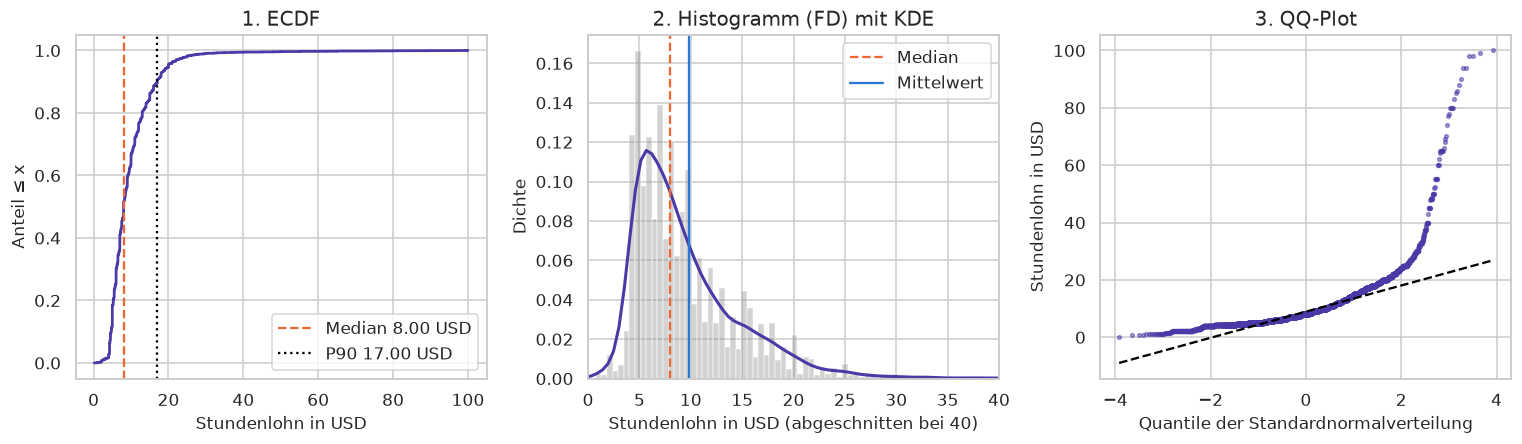

In [29]:
sortiert = np.sort(stundenlohn.to_numpy())
anteil = np.arange(1, len(sortiert) + 1) / len(sortiert)
normal, daten, steigung, achsenabschnitt = qq_punkte(stundenlohn)

fig, achsen = plt.subplots(1, 3, figsize=(14, 4.2))
# 1. ECDF mit Median und P90
achsen[0].step(sortiert, anteil, where="post", color=FARBE_NACHHER, linewidth=1.8)
achsen[0].axvline(median_s, color=FARBE_MEDIAN, linestyle="--", linewidth=1.5, label=f"Median {median_s:.2f} USD")
achsen[0].axvline(p90_s, color="black", linestyle=":", linewidth=1.5, label=f"P90 {p90_s:.2f} USD")
achsen[0].set(title="1. ECDF", xlabel="Stundenlohn in USD", ylabel="Anteil ≤ x")
achsen[0].legend(loc="lower right")
# 2. Histogramm (Freedman-Diaconis) mit KDE
achsen[1].hist(stundenlohn, bins="fd", density=True, color=FARBE_VORHER, alpha=0.35)
sns.kdeplot(stundenlohn, bw_adjust=1.0, color=FARBE_NACHHER, linewidth=2, ax=achsen[1])
achsen[1].axvline(median_s, color=FARBE_MEDIAN, linestyle="--", linewidth=1.5, label="Median")
achsen[1].axvline(stundenlohn.mean(), color=FARBE_MITTELWERT, linewidth=1.5, label="Mittelwert")
achsen[1].set(title="2. Histogramm (FD) mit KDE", xlabel="Stundenlohn in USD (abgeschnitten bei 40)", ylabel="Dichte",
              xlim=(0, 40))
achsen[1].legend(loc="upper right")
# 3. QQ-Plot gegen die Normalverteilung
achsen[2].scatter(normal, daten, s=6, color=FARBE_NACHHER, alpha=0.5)
achsen[2].plot(normal, achsenabschnitt + steigung * normal, color="black", linestyle="--", linewidth=1.5)
achsen[2].set(title="3. QQ-Plot", xlabel="Quantile der Standardnormalverteilung", ylabel="Stundenlohn in USD")
plt.tight_layout()
plt.show()

**Erkenntnis:**
- Alle drei Werkzeuge sagen dasselbe: Die ECDF steigt unten steil und zieht sich oben lang hin, Histogramm und KDE zeigen einen Gipfel um 5 bis 6 USD und eine lange rechte Flanke, der QQ-Plot ist ein Bogen mit stark ansteigendem rechtem Ende.
- Die Diagnose ist also eindeutig: rechtsschief mit schwerer rechter Flanke. Daraus folgt unser Satz für den Bericht:

  > "Der Stundenlohn ist rechtsschief mit schwerer rechter Flanke (QQ-Bogen). Wir berichten den Median von 8.00 USD mit IQR 5.85 bis 12.00 USD und das P90 von 17.00 USD. Die 403 Werte über dem Tukey-Zaun von 21.23 USD gehören zur Flanke und bleiben drin (n = 11'304, FD-Klassen, bw_adjust 1.0, whis 1.5)."

- Der Mittelwert von 9.78 USD hätte den typischen Stundenlohn um gut 20 % überschätzt.

> **Fazit ECDF und QQ**
>
> 1. Die **ECDF** vergleicht Gruppen ohne Klassenwahl: Die Kurve, die tiefer liegt, gehört zur Gruppe mit den grösseren Werten.
> 2. Der **QQ-Plot** zeigt die Abweichung von der Normalverteilung: Gerade heisst verträglich, Bogen heisst schief, S-Kurve heisst schwere Ränder.
> 3. Keine Diagnose aus einem einzelnen Plot: **ECDF, Histogramm mit KDE und QQ-Plot** zusammen, dann ein Satz mit allen Parametern.

---

## 4. Ausreisserregeln

Regeln markieren Werte, die weit vom Zentrum entfernt sind. Ob ein markierter Wert ein Fehler ist, entscheidet aber keine Regel. Wir vergleichen drei Regeln und gehen dann einen konkreten Fall bis zur Entscheidung durch.

### 4.1 Drei Regeln im Vergleich

Dieselben 63'186 Arbeitseinkommen ergeben je nach Regel 1'843, 2'458 oder 3'375 Prüfkandidaten. Welche Regel hat recht?

In [30]:
mittelwert = lohn_vollzeit.mean()
sd = lohn_vollzeit.std(ddof=1)
z = (lohn_vollzeit - mittelwert) / sd
z_markiert = z.abs() > 3

q1, q3 = lohn_vollzeit.quantile([0.25, 0.75])
iqr = q3 - q1
tukey_unten, tukey_oben = q1 - 1.5 * iqr, q3 + 1.5 * iqr
tukey_markiert = (lohn_vollzeit < tukey_unten) | (lohn_vollzeit > tukey_oben)

median = lohn_vollzeit.median()
mad = (lohn_vollzeit - median).abs().median()
m = 0.6745 * (lohn_vollzeit - median) / mad
m_markiert = m.abs() > 3.5
robuste_skala = mad / 0.6745     # |M| > 3.5 heisst |x - Median| > 3.5 · MAD / 0.6745

pd.DataFrame(
    {
        "untere Grenze": [mittelwert - 3 * sd, tukey_unten, median - 3.5 * robuste_skala],
        "obere Grenze": [mittelwert + 3 * sd, tukey_oben, median + 3.5 * robuste_skala],
        "markiert": [z_markiert.sum(), tukey_markiert.sum(), m_markiert.sum()],
        "Anteil in %": [z_markiert.mean() * 100, tukey_markiert.mean() * 100, m_markiert.mean() * 100],
    },
    index=["z-Score, |z| > 3", "Tukey, 1.5·IQR", "mod. z-Score, |M| > 3.5"],
).round(1)

,untere Grenze,obere Grenze,markiert,Anteil in %
"z-Score, |z| > 3",-32104.3,94715.9,1843,2.9
"Tukey, 1.5·IQR",-17500.0,74500.0,3375,5.3
"mod. z-Score, |M| > 3.5",-29003.7,81003.7,2458,3.9


In [31]:
print(f"von allen drei Regeln markiert:    {(z_markiert & tukey_markiert & m_markiert).sum()}")
print(f"nur von Tukey und mod. z-Score:    {(~z_markiert & tukey_markiert & m_markiert).sum()}")
print(f"nur von Tukey:                     {(~z_markiert & tukey_markiert & ~m_markiert).sum()}")
print(f"von keiner Regel markiert:         {(~z_markiert & ~tukey_markiert & ~m_markiert).sum()}")
print(f"\nDavon genau 99'999 USD (Top-Coding): {(lohn_vollzeit == 99999).sum()}")

von allen drei Regeln markiert:    1843
nur von Tukey und mod. z-Score:    615
nur von Tukey:                     917
von keiner Regel markiert:         59811

Davon genau 99'999 USD (Top-Coding): 1425


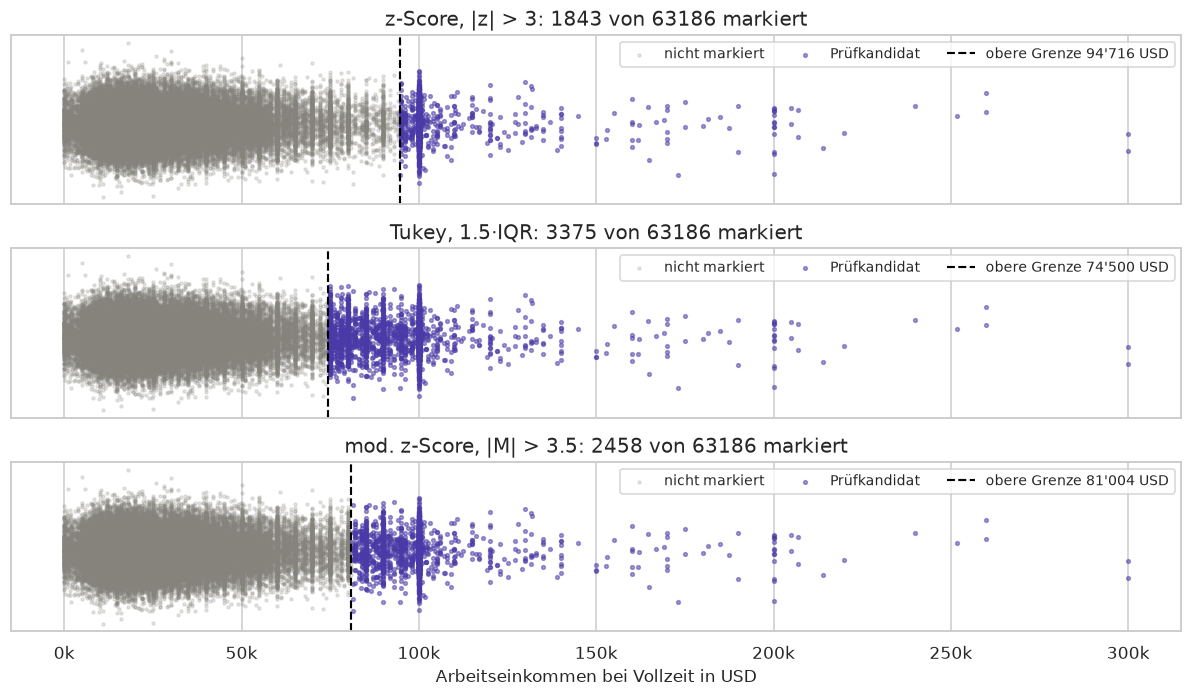

In [32]:
jitter = RNG.normal(0, 0.03, len(lohn_vollzeit))   # nur für die Darstellung: Punkte leicht streuen
werte = lohn_vollzeit.to_numpy()

fig, achsen = plt.subplots(3, 1, figsize=(11, 6.5), sharex=True)
for ax, maske, grenze, titel in zip(
    achsen,
    [z_markiert.to_numpy(), tukey_markiert.to_numpy(), m_markiert.to_numpy()],
    [mittelwert + 3 * sd, tukey_oben, median + 3.5 * robuste_skala],
    ["z-Score, |z| > 3", "Tukey, 1.5·IQR", "mod. z-Score, |M| > 3.5"],
):
    ax.scatter(werte[~maske], jitter[~maske], s=4, color=FARBE_VORHER, alpha=0.2, label="nicht markiert")
    ax.scatter(werte[maske], jitter[maske], s=6, color=FARBE_NACHHER, alpha=0.5, label="Prüfkandidat")
    ax.axvline(grenze, color="black", linestyle="--", linewidth=1.4, label=f"obere Grenze {zahl(grenze)} USD")
    ax.set(title=f"{titel}: {maske.sum()} von {len(werte)} markiert", yticks=[])
    ax.legend(loc="upper right", ncols=3, fontsize=9)
achsen[-1].set_xlabel("Arbeitseinkommen bei Vollzeit in USD")
achsen[-1].xaxis.set_major_formatter(lambda x, pos: f"{x / 1000:.0f}k")
plt.tight_layout()
plt.show()

**Erkenntnis:**
- Keine Regel hat allein recht, und alle drei markieren nur hohe Einkommen. Die Regeln sind ineinander verschachtelt: Alle 1'843 Fälle des z-Scores werden auch von den beiden anderen Regeln markiert, und alle Fälle des modifizierten z-Scores auch von Tukey.
- Der z-Score markiert am wenigsten, weil die lange Flanke selbst den Mittelwert und vor allem die SD nach oben zieht. Seine Grenze liegt bei 94'716 USD, knapp unter den 1'425 Werten von genau 99'999 USD (Top-Coding).
- Die unteren Grenzen sind bei allen drei Regeln negativ. Am unteren Rand kann deshalb keine Regel etwas finden, obwohl es dort unplausible Werte gibt (4.2).
- Bei rechtsschiefen Daten passen symmetrische Grenzen um Mittelwert oder Median schlecht. Die Grenzen gehören deshalb mindestens je sinnvoller Gruppe gerechnet, wie in 2.1 mit den Bildungsgruppen.

Der modifizierte z-Score braucht eine MAD grösser als 0. Bei den Arbeitswochen der Personen, die gearbeitet haben, ist das nicht der Fall:

In [33]:
wochen_gearbeitet = census.loc[census["WEEKS_WORKED"] > 0, "WEEKS_WORKED"]
median_w = wochen_gearbeitet.median()
mad_w = (wochen_gearbeitet - median_w).abs().median()
print(f"n = {len(wochen_gearbeitet)}, Median {median_w:.0f} Wochen, MAD {mad_w:.0f} Wochen")
print(f"Anteil mit genau 52 Wochen: {(wochen_gearbeitet == 52).mean():.1%}")
print(f"IQR: {wochen_gearbeitet.quantile(0.75) - wochen_gearbeitet.quantile(0.25):.0f} Wochen")

n = 103540, Median 52 Wochen, MAD 0 Wochen
Anteil mit genau 52 Wochen: 67.9%
IQR: 8 Wochen


**Erkenntnis:** 67.9 % haben genau 52 Wochen gearbeitet. Der Median ist deshalb 52, und mehr als die Hälfte der Abstände zum Median ist 0. Die MAD ist 0, und der modifizierte z-Score würde durch 0 teilen: Jeder Wert ausser 52 wäre unendlich weit weg und markiert. Die Regel ist hier nicht anwendbar. Auch Tukey hilft wenig, mit einem IQR von 8 Wochen würde alles unter 32 Wochen markiert. Bei so einer Variable beschreiben wir besser die Anteile (z.B. 67.9 % mit 52 Wochen), statt Ausreisser zu suchen.

### 4.2 Von der Markierung zur Entscheidung: ein Fall aus unseren Daten

Bei den Vollzeit-Erwerbstätigen haben 190 Personen ein Arbeitseinkommen von genau 1 USD im Jahr, obwohl sie mindestens 50 Wochen mit üblicherweise mindestens 35 Stunden pro Woche gearbeitet haben. Keine der drei Regeln markiert diese Werte. Was machen wir mit ihnen?

In [34]:
print("Die kleinsten Arbeitseinkommen bei Vollzeit:")
print(lohn_vollzeit.value_counts().sort_index().head(6))

ein_dollar = vollzeit[vollzeit["EARNINGS"] == 1]
print(f"\nVollzeit-Erwerbstätige mit genau 1 USD: {len(ein_dollar)} (im ganzen Datensatz: {(census['EARNINGS'] == 1).sum()})")
print("\nArt der Beschäftigung:")
print(ein_dollar["CLASS_OF_WORKER"].value_counts().head(3))
print(f"\nNegative Arbeitseinkommen im ganzen Datensatz (Verluste): {(census['EARNINGS'] < 0).sum()}")
print(f"\nMarkiert von z-Score / Tukey / mod. z-Score: "
      f"{z_markiert[ein_dollar.index].sum()} / {tukey_markiert[ein_dollar.index].sum()} / {m_markiert[ein_dollar.index].sum()}")

Die kleinsten Arbeitseinkommen bei Vollzeit:
EARNINGS
1.0     190
2.0       2
3.0       1
6.0       1
10.0      2
11.0      3
Name: count, dtype: int64

Vollzeit-Erwerbstätige mit genau 1 USD: 190 (im ganzen Datensatz: 372)

Art der Beschäftigung:
CLASS_OF_WORKER
Self-employed-not incorporated    186
Not in universe                     3
Private                             1
Name: count, dtype: int64

Negative Arbeitseinkommen im ganzen Datensatz (Verluste): 770

Markiert von z-Score / Tukey / mod. z-Score: 0 / 0 / 0


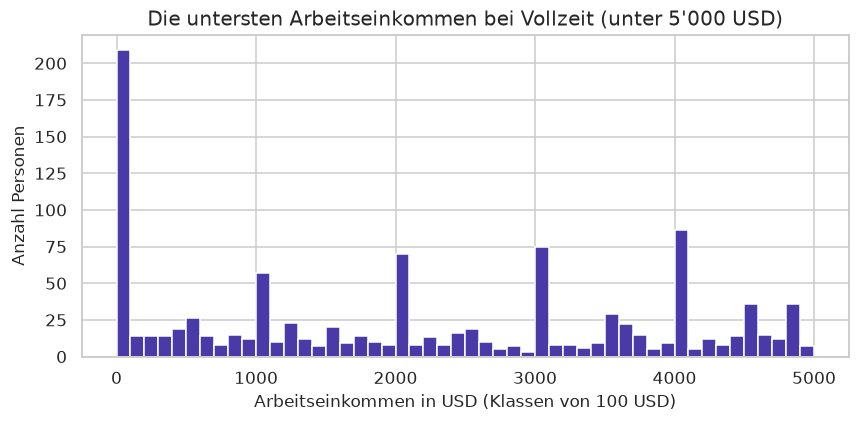

In [35]:
fig, ax = plt.subplots(figsize=(9, 3.8))
ax.hist(lohn_vollzeit[lohn_vollzeit < 5000], bins=np.arange(0, 5001, 100), color=FARBE_NACHHER)
ax.set(title="Die untersten Arbeitseinkommen bei Vollzeit (unter 5'000 USD)", xlabel="Arbeitseinkommen in USD (Klassen von 100 USD)",
       ylabel="Anzahl Personen")
plt.show()

Wir gehen die Prüffragen aus VL03 der Reihe nach durch:

1. **Kann der Wert vorkommen?** Als Lohn für ein volles Arbeitsjahr nicht. 186 der 190 Personen sind aber Selbständige ohne eingetragene Firma. Bei ihnen ist das Arbeitseinkommen der Gewinn, und ein Gewinn nahe 0 ist möglich.
2. **Stimmen Einheit und Erfassung?** Der Wert 1 kommt im ganzen Datensatz 372 Mal vor, die Werte 2 bis 11 USD nur je ein- bis dreimal. Das spricht für einen Code und nicht für echte Beträge. Verluste sind es nicht, die stehen im Datensatz als negative Werte. Was der Code genau bedeutet, müsste man im Codebook des CPS nachschlagen.
3. **Ist der Wert im richtigen Vergleich noch auffällig?** Bei Selbständigen ist ein sehr kleiner Gewinn weniger auffällig als bei Angestellten.
4. **Passt der Wert zu einem plausiblen Prozess?** Ja, wenn er für "kein Gewinn" steht.
5. **Immer noch unklar?** Ja. Dann gilt: behalten, Fallnotiz schreiben, Kennzahlen mit und ohne die Fälle vergleichen.

In [36]:
fallnotiz = pd.Series(
    {
        "Fälle": f"{len(ein_dollar)} Vollzeit-Erwerbstätige mit EARNINGS = 1 (Index z.B. {ein_dollar.index[:3].tolist()})",
        "Variable / Einheit": "EARNINGS, Arbeitseinkommen im Vorjahr in USD",
        "Wert": "genau 1 USD",
        "Regeln": "von keiner der drei Regeln markiert (alle unteren Grenzen sind negativ)",
        "Vergleichsgruppe": "Vollzeit-Ganzjahres-Erwerbstätige",
        "Quellenprüfung": "Wert kommt fast nur bei Selbständigen vor, vermutlich ein Code; im CPS-Codebook zu prüfen",
        "Entscheidung": "behalten, nicht ändern; robuste Kennzahlen berichten",
        "Begründung": "kein belegter Fehler; als Lohn unplausibel, aber als Code für Selbständige möglich",
        "Sensitivität": "Kennzahlen mit und ohne diese Fälle vergleichen (nächste Zelle)",
    },
    name="Fallnotiz",
)
fallnotiz.to_frame()

,Fallnotiz
Fälle,190 Vollzeit-Erwerbstätige mit EARNINGS = 1 (I...
Variable / Einheit,"EARNINGS, Arbeitseinkommen im Vorjahr in USD"
Wert,genau 1 USD
Regeln,von keiner der drei Regeln markiert (alle unte...
Vergleichsgruppe,Vollzeit-Ganzjahres-Erwerbstätige
Quellenprüfung,"Wert kommt fast nur bei Selbständigen vor, ver..."
Entscheidung,"behalten, nicht ändern; robuste Kennzahlen ber..."
Begründung,"kein belegter Fehler; als Lohn unplausibel, ab..."
Sensitivität,Kennzahlen mit und ohne diese Fälle vergleiche...


In [37]:
ohne_ein_dollar = lohn_vollzeit[lohn_vollzeit != 1]
winsorisiert = lohn_vollzeit.clip(upper=tukey_oben)


def kennzahlen(s):
    return {"n": len(s), "Mittelwert": s.mean(), "Median": s.median(), "SD (ddof=1)": s.std(ddof=1),
            "IQR": s.quantile(0.75) - s.quantile(0.25)}


pd.DataFrame(
    {
        "Rohdaten": kennzahlen(lohn_vollzeit),
        "ohne die 1-USD-Fälle": kennzahlen(ohne_ein_dollar),
        "Tukey-winsorisiert (oben)": kennzahlen(winsorisiert),
    }
).T.round(0)

,n,Mittelwert,Median,SD (ddof=1),IQR
Rohdaten,63186.0,31306.0,26000.0,21137.0,23000.0
ohne die 1-USD-Fälle,62996.0,31400.0,26000.0,21098.0,23000.0
Tukey-winsorisiert (oben),63186.0,30279.0,26000.0,17915.0,23000.0


**Erkenntnis:**
- Ohne die 190 Fälle ändern sich Median (26'000 USD) und IQR (23'000 USD) gar nicht, der Mittelwert steigt um knapp 100 USD. Für unsere robusten Kennzahlen spielt die Entscheidung also keine Rolle.
- Die Winsorisierung am oberen Tukey-Zaun verändert dagegen 3'375 Werte, senkt den Mittelwert um gut 1'000 USD und die SD um 3'222 USD. Das ist ein viel grösserer Eingriff und würde die Frage verändern, denn die hohen Einkommen sind echt.
- Die Regeln aus 4.1 hätten diese Fälle nie gefunden. Unplausible Werte am Rand findet man durch Hinsehen (Histogramm der kleinsten Werte, häufigste Werte) und Wissen über die Daten, nicht durch eine Abstandsregel.

> **Fazit Ausreisserregeln**
>
> 1. z-Score, Tukey und modifizierter z-Score markieren **Prüfkandidaten**, keine Fehler. Die Regel gehört mit ihren Parametern in den Bericht.
> 2. Bei rechtsschiefen Einkommen markieren alle Regeln nur oben. **Unplausible Werte nahe beim Zentrum** oder am unteren Rand findet erst die fachliche Prüfung.
> 3. Rohdaten bleiben unverändert. Eingriffe vergleichen wir als **Sensitivität** und halten sie in einer Fallnotiz fest.

---

## 5. Zusammenfassung: Entscheidungs-Log

Zum Schluss halten wir die Entscheidungen aus diesem Notebook fest, damit sie in den weiteren Notebooks gleich bleiben:

| Variable | Darstellung | Parameter | Entscheid |
|---|---|---|---|
| Arbeitseinkommen Vollzeit | Histogramm und KDE | FD-Klassen zum Prüfen, 2'500 USD für den Überblick; bw_adjust 1.0 (Scott) | rechtsschief (QQ-Bogen): Median und IQR; Rundungsspitzen und Top-Coding bei 99'999 USD nicht als Gipfel lesen |
| Gesamteinkommen nach Bildung | Boxplot auf Log-Skala | whis 1.5; 5'877 Werte ≤ 0 ausgeschlossen und vermerkt | der Median steigt mit jeder Bildungsstufe |
| Alter | Histogramm und KDE | 1 Jahr pro Klasse; bw_adjust 0.5, 1.0 und 2.0 geprüft | zwei stabile Gipfel um 5 und 34 Jahre; 90 heisst "90 und älter" |
| Arbeitswochen nach Altersgruppe | Violine | `inner="quartile"`, `cut=0` | zwei Gipfel bei 0 und 52 Wochen; nach Gruppe berichten |
| Arbeitseinkommen nach Geschlecht | ECDF | keine Klassen nötig | Kurven kreuzen sich nicht, Männer über den ganzen Bereich höher |
| Stundenlohn | ECDF, Histogramm mit KDE, QQ-Plot | FD-Klassen, bw_adjust 1.0, whis 1.5 | Median 8.00 USD, IQR 5.85 bis 12.00 USD, P90 17.00 USD |
| Ausreisser beim Arbeitseinkommen | z-Score, Tukey, mod. z-Score | \|z\| > 3, 1.5·IQR, \|M\| > 3.5 | Kandidaten behalten; 190 Werte von 1 USD mit Fallnotiz behalten |

Die wichtigsten drei Sätze aus diesem Notebook:

1. **Die Darstellung gehört zur Aussage.** Klassen und Bandbreite bestimmen, was man sieht. Bei unseren Daten zeigen feine Klassen vor allem Rundung und Top-Coding, keine echten Gipfel.
2. **Gruppen vergleichen wir mit Dichte, ECDF und Violine,** immer mit n je Gruppe, und die Einkommen auf der Log-Skala.
3. **Regeln markieren, die Prüfung entscheidet.** Die drei Ausreisserregeln finden nur hohe Einkommen, die zur Flanke gehören. Die auffälligen Werte von 1 USD hat keine Regel gefunden.